# 01 - Crowd-count model (train + validate + test)
**Question answered: HOW MANY PEOPLE ARE THERE?**   Self-contained notebook - no Python package, no helper files.

| | |
|---|---|
| **Reads** | ShanghaiTech A+B (head points) under `DATASET_ROOT`; your hard-negative crops (`NEGATIVE_DIR` or its zip) |
| **Writes** | `<OUTPUT_DIR>/models/crowd_count_model.pth` (+ `crowd_count_info.json`), metrics / figures under `<OUTPUT_DIR>/outputs/` |
| **Next** | `02_Motion_Model` (independent) and `03_Abnormal_Motion_Detection` (needs this model) |

### Logic (preserved from the original notebooks 00-02)
* ResNet-18 trunk, **point branch** (one head-point per anchor cell, confidence + offset) and **density branch** (support signal only). Anchors are matched to ground-truth heads by **Hungarian one-to-one matching**; losses: missed-head, false-positive / duplicate, coordinate, density, count-consistency.
* EMA weights, warm-up + cosine LR, AMP on CUDA, gradient clipping, checkpoint resume, early stopping, validation-based model selection.
* Validation-only tuning of the confidence threshold and duplicate radius, **regional refinement** (re-analyse dense regions at a higher scale), tiled inference, one-to-one evaluation (MAE, RMSE, NAE, precision, recall, F1, localisation error).
* **The final count = number of accepted predicted head points.** The density branch never adds people to the count.

### New: training on your hard negatives
Head-free background crops (`safe_negative`) are mixed into training (`NEG_FRACTION` of the items) so the model learns *what is not a head*. Only SAFE_NEGATIVE crops of TRAIN images are used, each re-verified against the ground-truth heads of its source image. Crops of validation images are kept out of training and measure false positives.
**No-regression rule:** the model trained with negatives replaces the original (baseline) only if its **validation F1 is not worse**; the notebook prints `SELECTED MODEL: BASELINE` or `ENHANCED`. The test set is never used for this decision.

## 0. Configuration

In [1]:
# ============================================================
# USER CONFIGURATION   (the only cell you normally need to edit)
# ============================================================
import os
NOTEBOOK_NAME = "01_Crowd_Count_Model"
DATASET_ROOT = r"C:\main project\stampede-risk-estimation\data\raw"     # folder that CONTAINS 'tubcrowdflow' (and 'shanghaitech'); searched automatically (~4 levels deep)
OUTPUT_DIR = "./crowdrisk_outputs"      # USE THE SAME FOLDER IN ALL FOUR NOTEBOOKS: trained models / metrics are exchanged through <OUTPUT_DIR>/models and <OUTPUT_DIR>/outputs
SEED = 42
USE_GPU = True                          # True -> CUDA if available, otherwise CPU

# Your hard-negative crops (output of the negative-sampling step: safe_negative/ uncertain/ rejected/ metadata/). If the folder does not exist the notebook looks for a
# '*negative*sampling*.zip' (next to DATASET_ROOT, next to this notebook, in the current folder) and extracts it automatically into OUTPUT_DIR.
NEGATIVE_DIR = r"C:\main project\stampede-risk-estimation\notebooks2\deliverable\outputs\hard_negative_mining\shanghai_negative_sampling"
TRAIN_COUNT_MODEL = True     # False -> only load <OUTPUT_DIR>/models/crowd_count_model.pth and re-run the test evaluation
USE_NEGATIVES = True         # train the counting model ALSO on your hard-negative crops (kept only if validation does not get worse)
NEG_FRACTION = 0.15          # probability that a training item is a negative (head-free) crop
NEG_VERIFY_MARGIN = 8        # px: a negative crop is dropped if ANY ground-truth head lies inside the crop enlarged by this margin
NEGATIVE_ZIP = None          # explicit path of the negative-sampling zip (None -> automatic search)
COUNT_PRESET = "auto"        # "auto" (gpu if CUDA else cpu_long) | "cpu" | "cpu_long" | "gpu"
COUNT_VARIANTS = ["D_point_density_hires"]     # any of A_density_only, B_point_only, C_point_density, D_point_density_hires
COUNT_OVERRIDES = {}         # e.g. {"epochs": 30, "batch": 4, "crop": 256, "time_budget_min": 120}
BASELINE_COUNT_CHECKPOINT = None   # optional: path of a count model you ALREADY trained (final_model.pth) -> used as the BASELINE instead of retraining it
REPORT_BASELINE_ON_TEST = True     # also report the non-selected count model on the test set (never used for selection)
MIN_GAIN = 0.0               # the ENHANCED (+negatives) model is selected only if validation F1 >= baseline + MIN_GAIN (0.0 -> "not worse")
SMOKE_TEST = os.environ.get("CROWDRISK_SMOKE", "0") == "1"   # True: tiny SYNTHETIC datasets + tiny models (checks the code path in minutes; metrics are meaningless)


In [2]:
# ---- SMOKE TEST mode (optional): everything below is replaced by tiny synthetic datasets / models so the WHOLE notebook runs in minutes ----
import tempfile
if SMOKE_TEST:
    _SMOKE_BASE = os.path.join(tempfile.gettempdir(), "crowdrisk_smoke")
    DATASET_ROOT = os.path.join(_SMOKE_BASE, "data", "raw"); NEGATIVE_DIR = os.path.join(_SMOKE_BASE, "shanghai_negative_sampling")
    if OUTPUT_DIR == "./crowdrisk_outputs": OUTPUT_DIR = os.path.join(_SMOKE_BASE, "outputs")
    WINDOW_LEN, HOP, FPS = 12, 4, 15.0; COUNT_PRESET = "smoke"; MOTION_WIDTHS = [96, 144, 192]; USE_RAFT = False; COUNT_STRIDE_TRAINING = 6; COUNT_EVERY = 3
    MOTION_TRAIN = dict(epochs=2, items_per_epoch=16, batch=4, crop=96, base=8, lr=1e-3); NEG_FRACTION = 0.3; VIDEO_PATH = None
    print("*** SMOKE TEST: synthetic data in", _SMOKE_BASE, "- code-path check only, all metrics are meaningless ***")


## 1. Environment and dependencies

In [3]:
# ---- dependency check: installs ONLY what is missing (a one-time `pip install torch torchvision` can be large) ---------------------
import sys, importlib, importlib.util, subprocess
_need = {"numpy": "numpy", "scipy": "scipy", "pandas": "pandas", "cv2": "opencv-python", "matplotlib": "matplotlib", "sklearn": "scikit-learn", "tqdm": "tqdm",
         "joblib": "joblib", "torch": "torch", "torchvision": "torchvision", "PIL": "pillow", "lightgbm": "lightgbm"}
if not NOTEBOOK_NAME.startswith("04"): _need.pop("lightgbm")                 # only the risk notebook needs the tree-model packages
_missing = [pip for mod, pip in _need.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("installing:", _missing)
    try: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])
    except Exception as e: print(f"[WARNING] automatic install failed ({e}). Run in a terminal, then restart the kernel:\n    {sys.executable} -m pip install " + " ".join(_missing))
else: print("all required packages are installed")
for _opt, _why in ((("lightgbm", "LightGBM risk model (falls back to XGBoost / scikit-learn HistGradientBoosting)"), ("xgboost", "XGBoost fallback")) if NOTEBOOK_NAME.startswith("04") else ()):
    if importlib.util.find_spec(_opt) is None: print(f"[info] optional package '{_opt}' not installed -> {_why}")


all required packages are installed


In [4]:
# ---- from notebook 00 cell 4
# ============================================================================
# Imports, environment helpers (portable: Colab / VS Code / plain Jupyter)
# ============================================================================
import os, sys, io, math, time, json, glob, copy, random, shutil, hashlib, warnings, zipfile, tempfile
import numpy as np, pandas as pd, cv2, scipy.io as sio
from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from scipy.ndimage import maximum_filter
import matplotlib
if os.environ.get("CC_HEADLESS"): matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageOps
from tqdm.auto import tqdm
warnings.filterwarnings("ignore"); cv2.setNumThreads(1)
IN_COLAB = "google.colab" in sys.modules

def pick_device(pref="auto"):
    """'auto' -> CUDA if available else CPU. Never hard-codes CUDA."""
    pref = (pref or "auto").lower()
    if pref == "cpu": return torch.device("cpu")
    if torch.cuda.is_available(): return torch.device("cuda")
    if pref in ("cuda", "gpu"): print("[warn] CUDA was requested but is not available -> using CPU.")
    return torch.device("cpu")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def json_safe(o):
    """Recursively convert numpy / tuple / Path objects into JSON-compatible python types."""
    if isinstance(o, dict): return {str(k): json_safe(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [json_safe(v) for v in o]
    if isinstance(o, np.generic): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (str, int, float, bool)) or o is None: return o
    return str(o)

def save_atomic(obj, path):
    tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)

def torch_load_safe(path, device):
    try: return torch.load(path, map_location=device, weights_only=True)
    except Exception: return torch.load(path, map_location=device, weights_only=False)      # our own files only

def ceil_to(x, m=32): return int(math.ceil(x / m) * m)

try: from IPython.display import display, Markdown
except Exception:
    display = print
    def Markdown(x): return x

# ---------------------------------------------------------------- default inference / refinement settings (shared by both notebooks)
DEFAULT_REFINE = dict(
    enabled=True, region_size=128,      # px (original image) of the analysis grid cells
    min_region_density=6.0,             # ignore regions whose density estimate is below this many people
    abs_gap=3.0, rel_gap=0.30,          # flag if (density - accepted points) >= max(abs_gap, rel_gap*density)
    min_uncertain=3,                    # ... or if >= this many uncertain (yellow) points sit in the region
    crop_margin=32,                     # px of context added around the region (overlap with neighbours)
    scale=2.0, scale_growth=1.5, max_scale=3.0,   # effective-resolution multiplier on iteration 0, growth per iteration, hard cap
    max_iters=2, max_regions=12,        # max refinement iterations / max regions re-analysed per image
    max_crop_pixels=1.5e6,              # memory guard for the up-scaled crop
    policy="replace_if_more")           # 'union' | 'replace_if_more' | 'replace'  (see _merge_region)

DEFAULT_INFER = dict(
    density_scale=10.0, min_long=640, max_long=1536, max_pixels=2.0e6, tile=768, tile_overlap=128,
    exposure_norm=True, exposure_target=0.42, min_candidate_conf=0.05, peak_min_value=0.01, amp=False,
    conf_accept=0.5, uncertain_ratio=0.5, dup_radius=3.0, refine=copy.deepcopy(DEFAULT_REFINE))




# ---- extra imports used by the motion / risk parts --------------------------------------------------------------------------------
import re, struct, datetime, dataclasses
from dataclasses import dataclass, field
from collections import deque
from scipy.ndimage import gaussian_filter, binary_dilation
import joblib
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score, average_precision_score, f1_score, roc_curve, precision_recall_curve, classification_report)


c:\main project\stampede-risk-estimation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
# ---- run folders, seeds, device, reproducibility record (the SAME OUTPUT_DIR is used by all four notebooks) -----------------------------------------
import datetime
SEED = int(SEED); set_seed(SEED)
OUTPUT_DIR = os.path.abspath(OUTPUT_DIR)
MODELS_DIR = os.path.join(OUTPUT_DIR, "models")
OUTPUTS = os.path.join(OUTPUT_DIR, "outputs")
METRICS_DIR, FIG_DIR, VIDEO_DIR, PRED_DIR = (os.path.join(OUTPUTS, d) for d in ("metrics", "figures", "videos", "predictions"))
WORK_DIR = os.path.join(OUTPUT_DIR, "work")                        # caches / checkpoints / extracted files (safe to delete, will be rebuilt)
COUNT_OUT = os.path.join(WORK_DIR, "count")                        # crowd-count training work folder (checkpoints, caches, tables)
CACHE_DIR = os.path.join(WORK_DIR, "cache")                        # TUB work-resolution cache + count cache
VIDEO_IN_DIR = os.path.join(OUTPUT_DIR, "videos_in")
for _d in (MODELS_DIR, METRICS_DIR, FIG_DIR, VIDEO_DIR, PRED_DIR, WORK_DIR, COUNT_OUT, CACHE_DIR, VIDEO_IN_DIR): os.makedirs(_d, exist_ok=True)
DEVICE = pick_device("auto" if USE_GPU else "cpu")
if DEVICE.type == "cuda": torch.backends.cudnn.benchmark = True
RUN_META = dict(notebook=NOTEBOOK_NAME, created=datetime.datetime.now().isoformat(timespec="seconds"), seed=SEED, device=str(DEVICE), smoke_test=SMOKE_TEST, torch=torch.__version__)
print(f"[{NOTEBOOK_NAME}] seed {SEED} | device {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else " (CPU only)") + f" | OUTPUT_DIR = {OUTPUT_DIR}")
print("trained models are exchanged between the notebooks through", MODELS_DIR)


[01_Crowd_Count_Model] seed 42 | device cpu (CPU only) | OUTPUT_DIR = c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs
trained models are exchanged between the notebooks through c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs\models


## 2. Architecture (configuration, image utilities, model)

In [6]:
# ============================================================================================================================
# CONFIGURATION (taken from notebook 00 cells 6 and 8; wider threshold grids, an extra long CPU preset and a training time budget added)
# configure() fills these module-level objects IN PLACE, because the functions below read them as globals.
# ============================================================================================================================
VARIANTS = {
    "A_density_only":        dict(kind="density", point=False, density=True,  point_stride=8, desc="ResNet-18 density model (baseline). Count = density sum; localisation only via density peaks."),
    "B_point_only":          dict(kind="point",   point=True,  density=False, point_stride=8, desc="P2PNet-inspired point proposals on stride-8 features, no density branch."),
    "C_point_density":       dict(kind="point",   point=True,  density=True,  point_stride=8, desc="point branch + density branch on a shared ResNet-18 trunk (multi-task)."),
    "D_point_density_hires": dict(kind="point",   point=True,  density=True,  point_stride=4, desc="as C, but the point head reads stride-4 features that fuse layer1 (higher-resolution path for small heads)."),
}
BASE_CFG = dict(
    val_fraction=0.15, max_long_side_train=2048, scale_range=(0.55, 2.2), p_flip=0.5, p_rot=0.4, rot_deg=12, p_persp=0.3, persp=0.08, p_head_centered=0.35,
    photometric=True, exposure_norm=True, exposure_norm_skip_p=0.15, exposure_target=0.42,
    stride=8, density_scale=10.0, min_sigma=1.0, max_sigma=6.0, knn_k=3, knn_beta=0.3, sparse_sigma=2.0,
    pretrained=True, fuse=128, freeze_stem=True, anchor_spacing=4, cls_prior=0.02,
    match_w_dist=0.05, match_w_cls=1.0, match_max_dist=24.0,
    w_fp=0.5, w_miss=1.0, w_coord=2.0, w_density=1.0, w_count=1.0, neg_norm_min=8, dens_w_pix=5.0, dens_w_loc=1.0, local_windows=(2, 4, 8),
    wd=1e-4, grad_clip=2.0, warmup_epochs=1, lr_backbone=1e-4, lr_head=5e-4, ema_decay=0.99, min_delta=1e-4, select_w_nae=0.25,
    tol_frac=0.5, tol_min=3.0, tol_max=16.0, tol_fixed=8.0, density_bins=(100, 400), nae_floor=10,
    # WIDER grids than the original notebooks (the original optimum sat on the edge of the grid: dup_radius 6.0 / conf 0.2)
    conf_grid=(0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9), dup_grid=(0.0, 2.0, 3.0, 4.0, 6.0, 8.0, 10.0, 12.0), peak_conf_grid=(0.01, 0.02, 0.03, 0.05, 0.08, 0.12, 0.2, 0.3),
    refine_grid=dict(policy=("replace_if_more", "union"), scale=(1.5, 2.0), rel_gap=(0.25, 0.45)), refine_min_gain=0.002,
    eval_max_images=None, keep_last_ckpt=False, pr_max_images=150, save_all_vis=True, panel_w=800, n_comparison=12, n_failure=8, time_budget_min=None,
)
_workers = 0 if (os.name == "nt" or (os.cpu_count() or 1) <= 4) else 2
PRESETS = dict(
    cpu=dict(crop=224, batch=8, samples_per_epoch=256, epochs=14, workers=_workers, amp=False, patience=5, val_every=2, val_stride=4, val_loss_items=24, tune_images=40, refine_tune_images=16),
    cpu_long=dict(crop=256, batch=8, samples_per_epoch=640, epochs=40, workers=_workers, amp=False, patience=8, val_every=2, val_stride=3, val_loss_items=32, tune_images=100, refine_tune_images=24),
    gpu=dict(crop=384, batch=16, samples_per_epoch=3200, epochs=60, workers=2 if os.name != "nt" else 0, amp=True, patience=12, val_every=1, val_stride=2, val_loss_items=96, tune_images=None, refine_tune_images=40),
    smoke=dict(crop=128, batch=2, samples_per_epoch=6, epochs=2, workers=0, amp=False, patience=2, val_every=1, val_stride=1, val_loss_items=4, tune_images=4, refine_tune_images=3, pretrained=False,
               conf_grid=(0.3, 0.5, 0.7), dup_grid=(0.0, 3.0), refine_grid=dict(policy=("replace_if_more",), scale=(2.0,), rel_gap=(0.3,)), n_comparison=3, n_failure=2),
)
SMOKE_INFER = dict(min_long=256, max_long=512, max_pixels=0.12e6, tile=256, tile_overlap=64)

CFG, INFER = {}, {}
S, STRIDE = 10.0, 8
OUT_DIR = "."
DEVICE = None
PRESET = None
VARIANT_NAMES = list(VARIANTS)


def spec_for(name):
    v = VARIANTS[name]; return dict(point=v["point"], density=v["density"], point_stride=v["point_stride"], anchor_spacing=CFG["anchor_spacing"], fuse=CFG["fuse"], cls_prior=CFG["cls_prior"], kind=v["kind"])


def configure(out_dir, preset="auto", device="auto", seed=42, variants=None, overrides=None, infer_overrides=None, resume=True, verbose=True):
    """Fill CFG / INFER / OUT_DIR / DEVICE ... (module globals) exactly like notebook 00 did. Returns the device."""
    global S, STRIDE, OUT_DIR, DEVICE, PRESET, VARIANT_NAMES
    DEVICE = pick_device(device); set_seed(seed)
    if DEVICE.type == "cuda": torch.backends.cudnn.benchmark = True
    PRESET = preset if preset != "auto" else ("gpu" if DEVICE.type == "cuda" else "cpu_long")
    assert PRESET in PRESETS, f"unknown preset '{PRESET}' (use auto | cpu | cpu_long | gpu | smoke)"
    if PRESET == "gpu" and DEVICE.type != "cuda": print("[warn] preset 'gpu' on a CPU-only machine will be extremely slow -> use 'cpu_long' or 'cpu'.")
    OUT_DIR = out_dir
    for sub in ("ckpt", "eval_cache", "figures", "tables", "visualisations", "final"): os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)
    CFG.clear(); CFG.update({**copy.deepcopy(BASE_CFG), **copy.deepcopy(PRESETS[PRESET]), **copy.deepcopy(overrides or {})})
    CFG["seed"] = seed; CFG["resume"] = resume; CFG["amp"] = bool(CFG["amp"] and DEVICE.type == "cuda")
    for k in ("tune_images", "eval_max_images"): CFG.setdefault(k, None)
    assert CFG["crop"] % 32 == 0, "crop must be a multiple of 32"
    INFER.clear(); INFER.update(copy.deepcopy(DEFAULT_INFER)); INFER["amp"] = CFG["amp"]; INFER["density_scale"] = CFG["density_scale"]; INFER["exposure_norm"] = CFG["exposure_norm"]; INFER["exposure_target"] = CFG["exposure_target"]
    if PRESET == "smoke": INFER.update(SMOKE_INFER)
    for k, v in (infer_overrides or {}).items(): INFER[k] = {**INFER[k], **v} if isinstance(v, dict) else v
    S = CFG["density_scale"]; STRIDE = CFG["stride"]; VARIANT_NAMES = list(variants or ["D_point_density_hires"])
    for v in VARIANT_NAMES: assert v in VARIANTS, f"unknown variant '{v}'. Available: {list(VARIANTS)}"
    if verbose:
        print(f"torch {torch.__version__} | device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else " (CPU only)") + f" | seed {seed}")
        print("preset:", PRESET, {k: CFG[k] for k in ("crop", "batch", "samples_per_epoch", "epochs", "workers", "amp", "patience")}); print("variants:", VARIANT_NAMES, "| outputs ->", os.path.abspath(OUT_DIR))
    return DEVICE


In [7]:
# ---- crowd-count configuration: ORIGINAL variants + the same variants trained ALSO on hard-negative crops ('__NEG') ------------------
for _b in COUNT_VARIANTS: assert _b in VARIANTS, f"unknown count variant {_b!r}; available: {list(VARIANTS)}"
if USE_NEGATIVES:
    for _b in list(COUNT_VARIANTS): VARIANTS[_b + "__NEG"] = {**VARIANTS[_b], "neg": True, "desc": VARIANTS[_b]["desc"] + "  + hard-negative (head-free) crops in training"}
COUNT_VARIANT_NAMES = [x for _b in COUNT_VARIANTS for x in ([_b] + ([_b + "__NEG"] if USE_NEGATIVES else []))]
DEVICE_COUNT = configure(COUNT_OUT, preset=COUNT_PRESET, device=("auto" if USE_GPU else "cpu"), seed=SEED, variants=COUNT_VARIANT_NAMES, overrides=COUNT_OVERRIDES, resume=True)
RUN_META.update(count_preset=PRESET, count_variants=COUNT_VARIANT_NAMES, count_cfg={k: CFG[k] for k in ("crop", "batch", "samples_per_epoch", "epochs", "amp", "patience")})


torch 2.11.0+cpu | device: cpu (CPU only) | seed 42
preset: cpu_long {'crop': 256, 'batch': 8, 'samples_per_epoch': 640, 'epochs': 40, 'workers': 0, 'amp': False, 'patience': 8}
variants: ['D_point_density_hires', 'D_point_density_hires__NEG'] | outputs -> c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs\work\count


In [8]:
# ---- from notebook 00 cell 10
# ============================================================================
# Image I/O, exposure normalisation (retained from notebook 12), synthetic data
# ============================================================================
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")
VIDEO_EXT = (".mp4", ".avi", ".mov", ".mkv", ".webm", ".m4v")
IMNET_MEAN = np.array([0.485, 0.456, 0.406], np.float32); IMNET_STD = np.array([0.229, 0.224, 0.225], np.float32)

def read_image_rgb(path):
    """Robust loader: EXIF rotation, grayscale, RGBA/palette, 16-bit -> uint8 RGB. Raises IOError with a clear message."""
    try:
        im = ImageOps.exif_transpose(Image.open(path))
        if im.mode in ("I;16", "I", "F"):
            a = np.array(im).astype(np.float32); im = Image.fromarray((a / max(float(a.max()), 1.0) * 255).astype(np.uint8))
        if im.mode in ("RGBA", "LA", "P"):
            im = im.convert("RGBA"); bg = Image.new("RGB", im.size, (127, 127, 127)); bg.paste(im, mask=im.split()[-1]); im = bg
        return np.ascontiguousarray(np.array(im.convert("RGB")))
    except Exception as e:
        raise IOError(f"Cannot read image '{path}': {e}") from e

def _f(img): return img.astype(np.float32) / 255.0
def _u8(x): return np.ascontiguousarray(np.clip(x * 255.0 + 0.5, 0, 255).astype(np.uint8))

def normalize_exposure(img, target=0.42):
    """Gamma + percentile stretch so dark / bright photos reach the network in a similar range.
    Applied in training (with a small skip probability) AND in every inference path."""
    x = _f(img); lum = 0.299 * x[..., 0] + 0.587 * x[..., 1] + 0.114 * x[..., 2]; m = float(lum[::2, ::2].mean())
    if m < 0.30 or m > 0.62:
        g = float(np.clip(np.log(target) / np.log(np.clip(m, 1e-3, 0.999)), 0.35, 2.5))
        x = np.power(x, g); lum = 0.299 * x[..., 0] + 0.587 * x[..., 1] + 0.114 * x[..., 2]
    lo, hi = np.percentile(lum[::2, ::2], (0.5, 99.5))
    if hi - lo > 0.08: x = 0.5 * x + 0.5 * np.clip((x - lo) / (hi - lo), 0, 1)
    return _u8(x)

def to_tensor(img): return torch.from_numpy(((_f(img) - IMNET_MEAN) / IMNET_STD).transpose(2, 0, 1).copy())

# ---------------------------------------------------------------- synthetic data (SMOKE TESTS / demos only)
def make_synthetic_crowd_image(w, h, n, rng):
    """Procedural 'crowd': dark head blobs with lighter bodies on a noisy background.
    ONLY used to smoke-test the code path. Counts/metrics on it are meaningless."""
    yy, xx = np.mgrid[0:h, 0:w]
    bg = np.stack([120 + 40 * np.sin(xx / 37.0), 130 + 30 * np.cos(yy / 41.0), 110 + 0 * xx], -1).astype(np.float32)
    img = np.clip(bg + rng.normal(0, 6, (h, w, 3)), 0, 255).astype(np.uint8)
    pts, tries = [], 0
    while len(pts) < n and tries < n * 50:
        tries += 1; x, y = rng.uniform(12, w - 12), rng.uniform(12, h - 24)
        if all((x - a) ** 2 + (y - b) ** 2 > 14 ** 2 for a, b in pts): pts.append((x, y))
    for x, y in pts:
        col = tuple(int(c) for c in rng.integers(20, 90, 3))
        cv2.ellipse(img, (int(x), int(y) + 14), (7, 11), 0, 0, 360, tuple(int(c) for c in rng.integers(90, 220, 3)), -1)
        cv2.circle(img, (int(x), int(y)), 5, col, -1)
    return img, np.asarray(pts, np.float32).reshape(-1, 2)

def save_gt_mat(path, pts):
    """Write a ShanghaiTech-style ground-truth file: image_info{1,1}{1,1}.location (Nx2) and .number."""
    st = np.zeros((1, 1), dtype=[("location", "O"), ("number", "O")])
    st[0, 0]["location"] = np.asarray(pts, np.float64).reshape(-1, 2); st[0, 0]["number"] = np.array([[len(pts)]], np.uint16)
    inner = np.empty((1, 1), dtype=object); inner[0, 0] = st
    outer = np.empty((1, 1), dtype=object); outer[0, 0] = inner
    sio.savemat(path, {"image_info": outer})

def write_synthetic_shanghaitech(root, n_train=(8, 10), n_test=(5, 6), seed=0):
    """Create a tiny dataset with the real ShanghaiTech folder layout (part_X_final/{train,test}_data/{images,ground_truth})."""
    rng = np.random.default_rng(seed)
    for pi, part in enumerate(("A", "B")):
        for si, split in enumerate(("train", "test")):
            n_img = (n_train, n_test)[si][pi]
            d_img = os.path.join(root, f"part_{part}_final", f"{split}_data", "images"); d_gt = os.path.join(root, f"part_{part}_final", f"{split}_data", "ground_truth")
            os.makedirs(d_img, exist_ok=True); os.makedirs(d_gt, exist_ok=True)
            for i in range(1, n_img + 1):
                w, h = (400, 300) if part == "A" else (448, 320)
                n = int(rng.integers(15, 70)) if part == "A" else int(rng.integers(5, 30))
                img, pts = make_synthetic_crowd_image(w, h, n, rng)
                cv2.imwrite(os.path.join(d_img, f"IMG_{i}.jpg"), img[..., ::-1]); save_gt_mat(os.path.join(d_gt, f"GT_IMG_{i}.mat"), pts)
    return root


In [9]:
# ---- from notebook 00 cell 18
# ============================================================================
# MODEL: ResNet-18 shared trunk  ->  Branch A (point proposals)  +  Branch B (density)
#
# NOT a reproduction of P2PNet. What is borrowed / changed:
#   borrowed : dense grid of point proposals, each with (head-confidence, offset), trained with one-to-one Hungarian matching
#   changed  : ResNet-18 trunk with L2/L3/L4 fusion + dilated context (from notebook 12) instead of VGG16-FPN;
#              optional stride-4 path that fuses layer1 (high-res) features for tiny heads;
#              an extra density branch that shares the trunk and is only used as a *supporting* signal.
# ============================================================================
def conv_bn(i, o, k=3, d=1):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=d * (k // 2), dilation=d, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

def make_anchors(h, w, stride, spacing, device="cpu"):
    """Anchor (x, y) pixel coordinates, ordering (row i, col j, sub-anchor k) -> (h*w*K, 2).
    Each feature cell holds K=(stride/spacing)^2 anchors on a regular grid with `spacing` pixels between them."""
    na = stride // spacing
    sub = (torch.arange(na, dtype=torch.float32, device=device) + 0.5) * spacing
    sy, sx = torch.meshgrid(sub, sub, indexing="ij"); oy, ox = sy.reshape(-1), sx.reshape(-1); K = na * na
    cy = torch.arange(h, dtype=torch.float32, device=device) * stride; cx = torch.arange(w, dtype=torch.float32, device=device) * stride
    Y = (cy[:, None, None] + oy[None, None, :]).expand(h, w, K); X = (cx[None, :, None] + ox[None, None, :]).expand(h, w, K)
    return torch.stack([X, Y], -1).reshape(-1, 2)

MODEL_SPEC_KEYS = ("point", "density", "point_stride", "anchor_spacing", "fuse", "cls_prior")

class CrowdPointNet(nn.Module):
    """forward(x) -> dict:
         'density' : (B,1,H/8,W/8)  non-negative map, sum/density_scale = count          (if density branch on)
         'logits'  : (B,A,2)        [background, head] logits for every anchor           (if point branch on)
         'offsets' : (B,A,2)        (dx,dy) in units of `point_stride` pixels
         'anchors' : (A,2)          anchor pixel coordinates in the network-input frame
       predicted head centre = anchor + offset * point_stride."""
    def __init__(self, point=True, density=True, point_stride=8, anchor_spacing=4, fuse=128, pretrained=True, freeze_stem=True, cls_prior=0.02):
        super().__init__()
        assert point or density, "at least one branch is required"
        assert point_stride in (4, 8) and point_stride % anchor_spacing == 0, "point_stride must be 4 or 8 and a multiple of anchor_spacing"
        self.point, self.density, self.point_stride, self.anchor_spacing, self.fuse_ch, self.cls_prior = bool(point), bool(density), point_stride, anchor_spacing, fuse, cls_prior
        try: r = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        except Exception as e:
            print("[warn] ImageNet weights unavailable -> RANDOM init (training will be much worse):", repr(e)[:120]); r = torchvision.models.resnet18(weights=None)
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = r.layer1, r.layer2, r.layer3, r.layer4
        self.p1, self.p2, self.p3, self.p4 = nn.Conv2d(64, fuse, 1), nn.Conv2d(128, fuse, 1), nn.Conv2d(256, fuse, 1), nn.Conv2d(512, fuse, 1)
        # shared multi-scale fusion at stride 8 (layers 2,3,4) + dilated context block (from notebook 12)
        self.fuse8 = nn.Sequential(conv_bn(fuse * 3, fuse), conv_bn(fuse, fuse))
        self.ctx = nn.ModuleList([conv_bn(fuse, fuse // 2, 3, d) for d in (1, 2, 4)]); self.ctx_merge = conv_bn(fuse // 2 * 3, fuse, 1)
        if self.density:
            self.den_head = nn.Sequential(conv_bn(fuse, 64), conv_bn(64, 32), nn.Conv2d(32, 1, 1)); nn.init.constant_(self.den_head[-1].bias, -5.0)
        if self.point:
            if point_stride == 4: self.fuse4 = nn.Sequential(conv_bn(fuse * 2, fuse), conv_bn(fuse, fuse))   # high-resolution path: up(F8) + layer1
            self.K = (point_stride // anchor_spacing) ** 2
            self.cls_tower = nn.Sequential(conv_bn(fuse, fuse), conv_bn(fuse, fuse)); self.reg_tower = nn.Sequential(conv_bn(fuse, fuse), conv_bn(fuse, fuse))
            self.cls_out = nn.Conv2d(fuse, self.K * 2, 3, padding=1); self.reg_out = nn.Conv2d(fuse, self.K * 2, 3, padding=1)
            nn.init.normal_(self.reg_out.weight, std=0.01); nn.init.zeros_(self.reg_out.bias)
            nn.init.normal_(self.cls_out.weight, std=0.01)
            b = torch.zeros(self.K, 2); b[:, 1] = math.log(cls_prior / (1 - cls_prior)); self.cls_out.bias.data = b.reshape(-1)   # start with p(head)=cls_prior
        self.freeze_stem = freeze_stem
        if freeze_stem:
            for m in (self.stem, self.layer1):
                for p in m.parameters(): p.requires_grad = False
    def train(self, mode=True):
        super().train(mode)
        if mode and self.freeze_stem:
            for m in (self.stem, self.layer1): m.eval()
        return self
    def forward(self, x):
        f1 = self.layer1(self.stem(x)); f2 = self.layer2(f1); f3 = self.layer3(f2); f4 = self.layer4(f3); hw = f2.shape[-2:]
        up = lambda t, s: F.interpolate(t, size=s, mode="bilinear", align_corners=False)
        z = self.fuse8(torch.cat([self.p2(f2), up(self.p3(f3), hw), up(self.p4(f4), hw)], 1))
        z = z + self.ctx_merge(torch.cat([c(z) for c in self.ctx], 1)); out = {}
        if self.density: out["density"] = F.softplus(self.den_head(z))
        if self.point:
            zp = self.fuse4(torch.cat([up(z, f1.shape[-2:]), self.p1(f1)], 1)) if self.point_stride == 4 else z
            cls = self.cls_out(self.cls_tower(zp)); reg = self.reg_out(self.reg_tower(zp)); B, _, h, w = cls.shape
            out["logits"] = cls.view(B, self.K, 2, h, w).permute(0, 3, 4, 1, 2).reshape(B, h * w * self.K, 2)
            out["offsets"] = reg.view(B, self.K, 2, h, w).permute(0, 3, 4, 1, 2).reshape(B, h * w * self.K, 2)
            out["anchors"] = make_anchors(h, w, self.point_stride, self.anchor_spacing, x.device)
        return out

def build_model(spec, pretrained=True, freeze_stem=True):
    return CrowdPointNet(pretrained=pretrained, freeze_stem=freeze_stem, **{k: spec[k] for k in MODEL_SPEC_KEYS if k in spec})

def count_params(m): return sum(p.numel() for p in m.parameters()), sum(p.numel() for p in m.parameters() if p.requires_grad)


## 3. Dataset: ShanghaiTech loading, augmentation, hard negatives

In [10]:
# ---- from notebook 00 cell 12
# ============================================================================
# DATASET FETCHING / LOADING / VALIDATION  (ShanghaiTech Part A + Part B)
# Layout used by your notebooks 10-13:  <root>/part_X_final/{train_data,test_data}/{images/IMG_n.jpg, ground_truth/GT_IMG_n.mat}
# ============================================================================
import re
def _subdir(parent, names):
    try: items = os.listdir(parent)
    except OSError: return None
    low = {i.lower(): i for i in items if os.path.isdir(os.path.join(parent, i))}
    for n in names:
        if n.lower() in low: return os.path.join(parent, low[n.lower()])
    return None

def find_part_dir(root, letter, max_depth=4):
    """Find the folder of ShanghaiTech part `letter` ('A'/'B') under root: part_A_final, part_A, Part_A, ... must contain train_data and test_data."""
    pat = re.compile(rf"^part_?{letter}(_|$|\b)", re.I); root = os.path.abspath(root)
    for dp, dn, _ in os.walk(root):
        if dp[len(root):].count(os.sep) >= max_depth: dn[:] = []; continue
        for d in dn:
            full = os.path.join(dp, d)
            if pat.match(d) and _subdir(full, ["train_data"]) and _subdir(full, ["test_data"]): return full
    return None

def candidate_roots(user_root):
    c = [user_root, os.environ.get("CC_ROOT")]
    c += [os.path.join(".", "data", "raw", "shanghaitech"), os.path.join(".", "data", "shanghaitech"), "./shanghaitech", "./ShanghaiTech", "../data/raw/shanghaitech", "../data/shanghaitech", "./data"]
    c += ["/content/drive/MyDrive/shanghaitech", "/content/drive/MyDrive/ShanghaiTech", "/content/drive/MyDrive/crowd_data/shanghaitech", "/content/shanghaitech", "/content/ShanghaiTech", "/content/data"]
    c += ["/kaggle/input"]
    c += [r"C:\main project\stampede-risk-estimation\data\raw\shanghaitech"]          # the location used by your earlier notebooks (10-13)
    return [x for x in c if x]

def maybe_extract_zip(roots, dest):
    """If a ShanghaiTech zip file is found next to the candidate roots, extract it (Colab: upload the zip to Drive/MyDrive)."""
    for r in roots:
        for base in {r, os.path.dirname(os.path.abspath(r))}:
            for z in glob.glob(os.path.join(base, "*.zip")):
                if "shanghai" in os.path.basename(z).lower():
                    print("extracting", z, "->", dest); os.makedirs(dest, exist_ok=True)
                    with zipfile.ZipFile(z) as zf: zf.extractall(dest)
                    return dest
    return None

def locate_shanghaitech(user_root=None, out_dir=None):
    tried = candidate_roots(user_root)
    for r in tried:
        if os.path.isdir(r) and find_part_dir(r, "A") and find_part_dir(r, "B"): return os.path.abspath(r)
    ex = maybe_extract_zip(tried, os.path.join(out_dir or ".", "_dataset_extracted")) if out_dir else None
    if ex and find_part_dir(ex, "A") and find_part_dir(ex, "B"): return ex
    raise FileNotFoundError("ShanghaiTech was not found. Searched:\n  " + "\n  ".join(tried) +
        "\n\nFix (any ONE of these):\n  1) set USER['dataset_root'] to the folder that contains part_A_final and part_B_final;\n  2) put the dataset at ./data/shanghaitech;"
        "\n  3) Colab: copy it to Google Drive (MyDrive/shanghaitech) and keep use_google_drive=True;\n  4) set the environment variable CC_ROOT.\nExpected layout: <root>/part_A_final/train_data/images/IMG_1.jpg and <root>/part_A_final/train_data/ground_truth/GT_IMG_1.mat")

def _find_points(obj, depth=0):
    """Descend nested MATLAB cell / struct arrays until the Nx2 head-point array ('location') is found."""
    if depth > 10: return None
    if isinstance(obj, np.ndarray):
        if obj.dtype.names and "location" in obj.dtype.names:
            for el in obj.reshape(-1):
                r = _find_points(el["location"], depth + 1)
                if r is not None: return r
            return None
        if obj.dtype == object:
            for el in obj.reshape(-1):
                r = _find_points(el, depth + 1)
                if r is not None: return r
            return None
        if obj.ndim == 2 and obj.shape[1] >= 2 and np.issubdtype(obj.dtype, np.number): return obj
        if obj.size == 0: return np.zeros((0, 2))
    return None

def load_points(path):
    """Head-centre points (N,2) float32 as [x, y] in ORIGINAL image pixels. Handles ShanghaiTech 'image_info', QNRF-style 'annPoints', .npy and text files."""
    ext = os.path.splitext(path)[1].lower()
    if ext == ".mat":
        m = sio.loadmat(path); pts = _find_points(m["image_info"]) if "image_info" in m else None
        if pts is None and "annPoints" in m: pts = m["annPoints"]
        if pts is None:
            pts = next((v for k, v in m.items() if not k.startswith("__") and isinstance(v, np.ndarray) and v.ndim == 2 and v.shape[1] >= 2 and np.issubdtype(v.dtype, np.number)), None)
        if pts is None: raise ValueError(f"unrecognised .mat structure in {path}")
    elif ext == ".npy": pts = np.load(path)
    else: pts = np.loadtxt(path, delimiter="," if "," in open(path).readline() else None, ndmin=2)
    pts = np.asarray(pts, np.float32)
    return pts[:, :2].copy() if pts.ndim == 2 and pts.shape[0] > 0 else np.zeros((0, 2), np.float32)

def find_gt(stem, gt_dir):
    for name in (f"GT_{stem}.mat", f"{stem}_ann.mat", f"{stem}.mat", f"GT_{stem}.npy", f"{stem}.npy", f"{stem}.txt", f"{stem}.csv"):
        p = os.path.join(gt_dir, name)
        if os.path.exists(p): return p
    return None

def build_samples(img_dir, gt_dir, part, split, issues):
    """One dict per image. Defensive: unreadable images, missing / malformed GT, NaN and out-of-image points are reported in `issues` and never silently kept."""
    out = []
    for f in sorted(os.listdir(img_dir)):
        if not f.lower().endswith(IMG_EXT): continue
        stem, p = os.path.splitext(f)[0], os.path.join(img_dir, f)
        try:
            with Image.open(p) as im: im.verify()
            with Image.open(p) as im: W, H = ImageOps.exif_transpose(im).size
        except Exception as e: issues.append(dict(part=part, split=split, image=f, issue=f"corrupted image: {e}"[:120])); continue
        g = find_gt(stem, gt_dir)
        if g is None: issues.append(dict(part=part, split=split, image=f, issue="missing GT file")); continue
        try: pts = load_points(g)
        except Exception as e: issues.append(dict(part=part, split=split, image=f, issue=f"bad GT: {e}"[:120])); continue
        n0 = len(pts); pts = pts[np.isfinite(pts).all(1)]
        if len(pts) < n0: issues.append(dict(part=part, split=split, image=f, issue=f"{n0 - len(pts)} non-finite points dropped"))
        inb = (pts[:, 0] >= 0) & (pts[:, 0] < W) & (pts[:, 1] >= 0) & (pts[:, 1] < H)
        if (~inb).any(): issues.append(dict(part=part, split=split, image=f, issue=f"{int((~inb).sum())} out-of-image points dropped")); pts = pts[inb]
        if len(pts) == 0: issues.append(dict(part=part, split=split, image=f, issue="no annotated points (kept; count=0)"))
        out.append(dict(img=p, stem=stem, uid=f"{part}_{split}_{stem}", pts=pts, count=len(pts), part=part, split=split, W=W, H=H))   # uid: ShanghaiTech REUSES file names across train/test, so names alone are not unique
    return out

def stratified_val_split(samples, frac):
    """Deterministic, count-stratified train/val split (nb12): sorted by count, every k-th image goes to validation."""
    order = np.argsort([s["count"] for s in samples]); k = max(2, int(round(1 / frac))); val_idx = set(order[k // 2::k].tolist())
    return [s for i, s in enumerate(samples) if i not in val_idx], [s for i, s in enumerate(samples) if i in val_idx]

def load_shanghaitech(root, val_fraction):
    issues, train, val, test, paths = [], [], [], [], {}
    for part in ("A", "B"):
        pdir = find_part_dir(root, part); paths[part] = pdir
        tr_dir, te_dir = _subdir(pdir, ["train_data"]), _subdir(pdir, ["test_data"])
        for d, nm in ((tr_dir, "train_data"), (te_dir, "test_data")):
            if not (_subdir(d, ["images"]) and _subdir(d, ["ground_truth", "ground-truth", "groundtruth"])): raise FileNotFoundError(f"{d} must contain 'images' and 'ground_truth' folders.")
        tr_all = build_samples(_subdir(tr_dir, ["images"]), _subdir(tr_dir, ["ground_truth", "ground-truth", "groundtruth"]), part, "train", issues)
        tr, va = stratified_val_split(tr_all, val_fraction)
        for s in tr: s["split"] = "train"
        for s in va: s["split"] = "val"
        train += tr; val += va
        test += build_samples(_subdir(te_dir, ["images"]), _subdir(te_dir, ["ground_truth", "ground-truth", "groundtruth"]), part, "test", issues)
    return train, val, test, pd.DataFrame(issues, columns=["part", "split", "image", "issue"]), paths

def quick_hash(path):
    """Full-file SHA-1 (the original notebooks hashed only the first 64 KB; that can miss/over-match duplicates)."""
    h = hashlib.sha1()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""): h.update(chunk)
    return f"{os.path.getsize(path)}-{h.hexdigest()}"

def verify_split(train, val, test):
    """Leakage checks. NOTE: ShanghaiTech re-uses file names (train IMG_1 and test IMG_1 are different images), so identity is checked by
    absolute path and by a content fingerprint, never by name alone."""
    paths = {n: [os.path.abspath(s["img"]) for s in ss] for n, ss in (("train", train), ("val", val), ("test", test))}
    for n, p in paths.items(): assert len(p) == len(set(p)), f"duplicate file paths inside {n}"
    for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
        inter = set(paths[a]) & set(paths[b]); assert not inter, f"LEAK: {len(inter)} files shared between {a} and {b}: {list(inter)[:3]}"
    assert all(s["split"] == "test" for s in test) and all(s["split"] in ("train", "val") for s in train + val)
    h = {n: {quick_hash(s["img"]) for s in ss} for n, ss in (("train", train + val), ("test", test))}; dup = h["train"] & h["test"]
    if dup: print(f"[WARN] {len(dup)} test images have byte-identical content fingerprints to train/val images (possible duplicate files)!")
    print("split verification OK -> disjoint file sets:", {n: len(v) for n, v in paths.items()}, "| train/test content-duplicate fingerprints:", len(dup))
    return len(dup)

def describe_samples(name, ss):
    c = np.array([s["count"] for s in ss]) if ss else np.array([0]); print(f"{name:6s} n={len(ss):4d}  heads min/median/mean/max = {c.min():.0f}/{np.median(c):.0f}/{c.mean():.0f}/{c.max():.0f}  total heads={c.sum():.0f}")


In [11]:
# ---- from notebook 00 cell 16
# ============================================================================
# DENSITY TARGETS + AUGMENTATION (points are transformed with the image; counts are recomputed from points that survive the crop)
# ============================================================================
def make_density(pts, h, w, cfg):
    """(N,2) points of an h x w image -> (h/stride, w/stride) map that sums to #points inside. Adaptive Gaussians (kNN distance), sub-pixel splatting (nb12)."""
    st = cfg["stride"]; mh, mw = h // st, w // st; out = np.zeros((mh, mw), np.float32)
    if len(pts) == 0: return out
    p = np.asarray(pts, np.float64) / st; p = p[(p[:, 0] >= 0) & (p[:, 0] < mw) & (p[:, 1] >= 0) & (p[:, 1] < mh)]; n = len(p)
    if n == 0: return out
    if n >= cfg["knn_k"] + 1:
        d, _ = cKDTree(p).query(p, k=cfg["knn_k"] + 1); sig = np.clip(cfg["knn_beta"] * d[:, 1:].mean(1), cfg["min_sigma"], cfg["max_sigma"])
    else: sig = np.full(n, cfg["sparse_sigma"])
    sig = np.round(sig * 2) / 2; fx, fy = p[:, 0] - 0.5, p[:, 1] - 0.5; ix, iy = np.floor(fx).astype(int), np.floor(fy).astype(int); dx, dy = fx - ix, fy - iy
    for s_ in np.unique(sig):
        m = sig == s_; tmp = np.zeros((mh, mw), np.float32)
        for oy, ox, wt in ((0, 0, (1 - dy) * (1 - dx)), (0, 1, (1 - dy) * dx), (1, 0, dy * (1 - dx)), (1, 1, dy * dx)):
            np.add.at(tmp, (np.clip(iy[m] + oy, 0, mh - 1), np.clip(ix[m] + ox, 0, mw - 1)), wt[m].astype(np.float32))
        out += cv2.GaussianBlur(tmp, (0, 0), float(s_), borderType=cv2.BORDER_CONSTANT)
    return out

def op_gray(img): g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY); return np.ascontiguousarray(np.repeat(g[..., None], 3, 2))
def op_gamma_gain(img, gamma, gain): return _u8(gain * np.power(_f(img), gamma))
def op_contrast(img, f): x = _f(img); m = x.mean(); return _u8((x - m) * f + m)
def op_saturation(img, f):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32); hsv[..., 1] = np.clip(hsv[..., 1] * f, 0, 255); return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
def op_color_cast(img, gains): return _u8(_f(img) * np.asarray(gains, np.float32)[None, None, :])
def op_noise(img, sigma, rng): x = _f(img); return _u8(x + sigma * rng.normal(0, 1, x.shape).astype(np.float32))
def op_blur(img, sigma): return cv2.GaussianBlur(img, (0, 0), sigma)
def op_jpeg(img, q):
    ok, enc = cv2.imencode(".jpg", np.ascontiguousarray(img[..., ::-1]), [cv2.IMWRITE_JPEG_QUALITY, int(q)]); return np.ascontiguousarray(cv2.imdecode(enc, cv2.IMREAD_COLOR)[..., ::-1])
def op_lowres(img, f):
    h, w = img.shape[:2]; small = cv2.resize(img, (max(8, int(w * f)), max(8, int(h * f))), interpolation=cv2.INTER_AREA); return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)

def random_photometric(img, rng):
    """Colour / exposure / sensor augmentation. Never moves pixels, so point labels stay exact."""
    U = rng.uniform
    if rng.random() < 0.15: img = op_gray(img)
    else:
        if rng.random() < 0.30: img = op_color_cast(img, [U(.75, 1.25), U(.88, 1.12), U(.75, 1.25)])
        if rng.random() < 0.40: img = op_saturation(img, U(0.3, 1.8))
    r = rng.random()
    if r < 0.15: img = op_noise(op_gamma_gain(img, U(1.4, 2.6), U(0.3, 0.8)), U(0.01, 0.04), rng)      # low light + noise
    elif r < 0.22: img = op_gamma_gain(img, U(0.5, 0.8), U(1.0, 1.5))                                  # over-exposure
    elif r < 0.80: img = op_contrast(op_gamma_gain(img, U(0.8, 1.25), U(0.75, 1.25)), U(0.75, 1.3))
    if rng.random() < 0.15: img = op_lowres(img, U(0.4, 0.8))
    if rng.random() < 0.15: img = op_blur(img, U(0.5, 1.8))
    if rng.random() < 0.25: img = op_noise(img, U(0.005, 0.03), rng)
    if rng.random() < 0.30: img = op_jpeg(img, U(30, 90))
    return img

def _hom(m23): return np.vstack([m23, [0, 0, 1]])
def sample_view(img, pts, ow, oh, rng, cfg):
    """Random geometric view (scale / flip / rotation / perspective / crop) of (img, pts) as an (oh, ow) window.
    ONE 3x3 matrix is applied to image and points; points outside the window are dropped, so len(points_out) is the true count."""
    H0, W0 = img.shape[:2]; s = float(np.exp(rng.uniform(np.log(cfg["scale_range"][0]), np.log(cfg["scale_range"][1]))))
    if s < 0.9:
        nw, nh = max(8, int(round(W0 * s))), max(8, int(round(H0 * s))); img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA)
        if len(pts): pts = pts * np.array([nw / W0, nh / H0], np.float32)
        s_rem = 1.0
    else: s_rem = s
    H, W = img.shape[:2]; M = np.eye(3)
    if rng.random() < cfg["p_flip"]: M = np.array([[-1, 0, W], [0, 1, 0], [0, 0, 1.0]]) @ M
    if rng.random() < cfg["p_rot"]: M = _hom(cv2.getRotationMatrix2D((W / 2, H / 2), rng.uniform(-cfg["rot_deg"], cfg["rot_deg"]), 1.0)) @ M
    if rng.random() < cfg["p_persp"]:
        j = cfg["persp"]; src = np.float32([[0, 0], [W, 0], [W, H], [0, H]]); dst = (src + rng.uniform(-j, j, (4, 2)).astype(np.float32) * np.float32([W, H])).astype(np.float32)
        if cv2.isContourConvex(dst.reshape(-1, 1, 2)) and cv2.contourArea(dst) > 0.5 * W * H: M = cv2.getPerspectiveTransform(src, dst).astype(np.float64) @ M
    M = np.diag([s_rem, s_rem, 1.0]) @ M
    corners = cv2.perspectiveTransform(np.float32([[0, 0], [W, 0], [W, H], [0, H]])[None], M)[0]; minx, miny = corners.min(0); maxx, maxy = corners.max(0)
    tp = cv2.perspectiveTransform(pts.astype(np.float32)[None], M)[0] if len(pts) else np.zeros((0, 2), np.float32); cx = cy = None
    if len(tp) and rng.random() < cfg["p_head_centered"]: cx, cy = tp[rng.integers(len(tp))]
    def pick(lo, hi, size, center):
        if hi - lo <= size: return (lo + hi - size) / 2
        x0 = rng.uniform(lo, hi - size) if center is None else center - size / 2 + rng.uniform(-.3, .3) * size
        return float(np.clip(x0, lo, hi - size))
    x0, y0 = pick(minx, maxx, ow, cx), pick(miny, maxy, oh, cy); M2 = np.array([[1, 0, -x0], [0, 1, -y0], [0, 0, 1.0]]) @ M
    border = tuple(int(v) for v in img[::8, ::8].reshape(-1, 3).mean(0))
    out = cv2.warpPerspective(img, M2, (ow, oh), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=border)
    if len(pts):
        q = cv2.perspectiveTransform(pts.astype(np.float32)[None], M2)[0]; q = q[(q[:, 0] >= 0) & (q[:, 0] < ow) & (q[:, 1] >= 0) & (q[:, 1] < oh)]
    else: q = np.zeros((0, 2), np.float32)
    return np.ascontiguousarray(out), q.astype(np.float32)

class CrowdTrainSet(Dataset):
    """Unlimited fresh random views (`samples_per_epoch` items/epoch) with count-balanced sampling.
    train=False -> deterministic, un-augmented crops (used only for the validation LOSS). Each item:
      image (3,c,c), density (1,c/8,c/8)*S, points (N,2) in crop pixels, count = number of points inside THIS crop."""
    def __init__(self, samples, cfg, train=True, n_items=None):
        self.s, self.cfg, self.train, self.epoch = samples, cfg, train, 0; self.n = n_items or cfg["samples_per_epoch"]
        counts = np.array([x["count"] for x in samples]); bin_of = np.digitize(counts, np.quantile(counts, [0.2, 0.4, 0.6, 0.8]))
        self.bins = [np.where(bin_of == b)[0] for b in range(5) if (bin_of == b).any()]
        self.cfg_v = {**cfg, "scale_range": (1.0, 1.0), "p_flip": 0.0, "p_rot": 0.0, "p_persp": 0.0, "p_head_centered": 0.5}
    def set_epoch(self, ep): self.epoch = ep
    def __len__(self): return self.n
    def __getitem__(self, idx):
        cfg, c = (self.cfg if self.train else self.cfg_v), self.cfg["crop"]
        rng = np.random.default_rng([self.cfg["seed"], self.epoch if self.train else 0, idx, int(self.train)])      # reproducible, worker-safe
        if self.train: b = self.bins[rng.integers(len(self.bins))]; smp = self.s[b[rng.integers(len(b))]]
        else: smp = self.s[idx % len(self.s)]
        img = read_image_rgb(smp["img"]); pts = smp["pts"].copy(); L = max(img.shape[:2])
        if L > cfg["max_long_side_train"]:
            f = cfg["max_long_side_train"] / L; img = cv2.resize(img, (int(img.shape[1] * f), int(img.shape[0] * f)), interpolation=cv2.INTER_AREA); pts = pts * f
        v, q = sample_view(img, pts, c, c, rng, cfg)
        if self.train and cfg["photometric"]: v = random_photometric(v, rng)
        if cfg["exposure_norm"] and (not self.train or rng.random() >= cfg["exposure_norm_skip_p"]): v = normalize_exposure(v, cfg["exposure_target"])
        den = make_density(q, c, c, cfg)
        return dict(image=to_tensor(v), density=torch.from_numpy(den * cfg["density_scale"]).unsqueeze(0), points=torch.from_numpy(q), count=torch.tensor(float(len(q))))

def collate(batch):
    return dict(image=torch.stack([b["image"] for b in batch]), density=torch.stack([b["density"] for b in batch]), points=[b["points"] for b in batch], count=torch.stack([b["count"] for b in batch]))


In [12]:
# ---- SMOKE data (only when SMOKE_TEST): tiny synthetic ShanghaiTech + TUB + negative crops in the REAL folder layouts -------------------
def make_smoke_negatives(sh_root, neg_dir, n_per_image=2, crop=128, margin=24, seed=0):
    """Head-free crops of synthetic ShanghaiTech TRAIN images, written in the same layout/CSV columns as the real negative-sampling output."""
    rng = np.random.default_rng(seed); rows = []; os.makedirs(os.path.join(neg_dir, "safe_negative"), exist_ok=True); os.makedirs(os.path.join(neg_dir, "metadata"), exist_ok=True)
    for part in ("A", "B"):
        idir = os.path.join(sh_root, f"part_{part}_final", "train_data", "images"); gdir = os.path.join(sh_root, f"part_{part}_final", "train_data", "ground_truth")
        for f in sorted(os.listdir(idir)):
            stem = os.path.splitext(f)[0]; img = read_image_rgb(os.path.join(idir, f)); pts = load_points(find_gt(stem, gdir)); H, W = img.shape[:2]; k = 0
            for _ in range(60):
                if k >= n_per_image: break
                x0, y0 = int(rng.integers(0, W - crop)), int(rng.integers(0, H - crop))
                inside = (pts[:, 0] >= x0 - margin) & (pts[:, 0] < x0 + crop + margin) & (pts[:, 1] >= y0 - margin) & (pts[:, 1] < y0 + crop + margin) if len(pts) else np.zeros(0, bool)
                if inside.any(): continue
                k += 1; sid = f"{part}_train_{stem}__NEG_{k:03d}"; fn = f"{sid}.jpg"; cv2.imwrite(os.path.join(neg_dir, "safe_negative", fn), img[y0:y0 + crop, x0:x0 + crop][..., ::-1])
                rows.append(dict(sample_id=sid, uid=f"{part}_train_{stem}", source_image=f, part=part, split="train", sample_type="SAFE_NEGATIVE", state="VALID", label="negative", negative_type="safe_background",
                                 path=f"shanghai_negative_sampling/safe_negative/{fn}", crop_x=x0, crop_y=y0, crop_width=crop, crop_height=crop, crop_scale=1.0, W=W, H=H, negative_head_margin=margin))
    pd.DataFrame(rows).to_csv(os.path.join(neg_dir, "metadata", "negative_samples.csv"), index=False); return len(rows)

if SMOKE_TEST:
    _sh = os.path.join(DATASET_ROOT, "shanghaitech")
    if not os.path.isdir(os.path.join(_sh, "part_A_final")): write_synthetic_shanghaitech(_sh)
    if not os.path.isdir(os.path.join(NEGATIVE_DIR, "safe_negative")): print("synthetic negative crops:", make_smoke_negatives(_sh, NEGATIVE_DIR))


In [13]:
# ---- ShanghaiTech (head-point annotations). TUB CrowdFlow has NO head annotations, so the counting model is supervised on ShanghaiTech A+B ----
SHANGHAI_ROOT, COUNT_DATA_OK = None, False
try:
    SHANGHAI_ROOT = locate_shanghaitech(DATASET_ROOT, COUNT_OUT); COUNT_DATA_OK = True
except FileNotFoundError as e:
    if TRAIN_COUNT_MODEL: raise FileNotFoundError(str(e) + "\n\nThe crowd-count model needs ShanghaiTech (head points) for training/evaluation. TUB CrowdFlow has no head annotations. Either provide ShanghaiTech under DATASET_ROOT or set TRAIN_COUNT_MODEL=False and place a trained model at " + os.path.join(MODELS_DIR, "crowd_count_model.pth"))
    print("[info] ShanghaiTech not found -> count-model training and count test-evaluation are skipped (a trained model will be loaded).")
train_samples, val_samples, test_samples, ISSUES = [], [], [], pd.DataFrame()
if COUNT_DATA_OK:
    print("ShanghaiTech root:", SHANGHAI_ROOT)
    train_samples, val_samples, test_samples, ISSUES, PART_DIRS = load_shanghaitech(SHANGHAI_ROOT, CFG["val_fraction"])
    if min(len(train_samples), len(val_samples), len(test_samples)) == 0: raise RuntimeError("Empty train/val/test split - check the ShanghaiTech folders.")
    for nm, ss in (("train", train_samples), ("val", val_samples), ("test", test_samples)): describe_samples(nm, ss)
    verify_split(train_samples, val_samples, test_samples)
    assert len(train_samples) > 0 and len(val_samples) > 0 and len(test_samples) > 0
    print("validation images are carved out of the official TRAIN folders (count-stratified, deterministic); the official TEST folders are only used for the final evaluation.")
    print(f"annotation / image issues found: {len(ISSUES)}"); ISSUES.to_csv(os.path.join(METRICS_DIR, "count_dataset_issues.csv"), index=False)


ShanghaiTech root: C:\main project\stampede-risk-estimation\data\raw
train  n= 600  heads min/median/mean/max = 12/166/302/3138  total heads=180951
val    n= 100  heads min/median/mean/max = 15/167/306/2650  total heads=30613
test   n= 498  heads min/median/mean/max = 9/158/237/2256  total heads=117983
[WARN] 1 test images have byte-identical content fingerprints to train/val images (possible duplicate files)!
split verification OK -> disjoint file sets: {'train': 600, 'val': 100, 'test': 498} | train/test content-duplicate fingerprints: 1
validation images are carved out of the official TRAIN folders (count-stratified, deterministic); the official TEST folders are only used for the final evaluation.
annotation / image issues found: 286


In [14]:
# ============================================================================================================================
# HARD-NEGATIVE CROPS (head-free background crops of ShanghaiTech TRAIN images) -> extra training signal "what is NOT a head".
#   * only SAFE_NEGATIVE / VALID crops are used ('uncertain' and 'rejected' crops may contain heads and are NEVER used);
#   * every crop is re-verified against the ground-truth heads of its source image (no head inside the crop + NEG_VERIFY_MARGIN px);
#   * crops whose source image is in the VALIDATION split are NOT used for training - they form a held-out set that measures false positives.
# ============================================================================================================================
def locate_negative_dir(neg_dir, zip_path=None, extract_to=None):
    """Return the folder that contains safe_negative/ (extracting a '*negative*sampling*.zip' automatically when the folder does not exist)."""
    def has(d): return bool(d) and os.path.isdir(os.path.join(d, "safe_negative"))
    if has(neg_dir): return neg_dir
    if neg_dir and os.path.isdir(neg_dir):
        for dp, dn, _ in os.walk(neg_dir):
            if "safe_negative" in dn: return dp
            if dp[len(neg_dir):].count(os.sep) >= 3: dn[:] = []
    zips = [zip_path] if zip_path else []
    if not zips:
        bases = [os.path.dirname(neg_dir or ""), DATASET_ROOT, os.path.dirname(DATASET_ROOT or ""), os.getcwd(), os.path.dirname(os.getcwd()), OUTPUT_DIR, os.path.join(OUTPUT_DIR, "..")]
        for b in dict.fromkeys(os.path.abspath(x) for x in bases if x and os.path.isdir(x)):
            zips += [z for z in glob.glob(os.path.join(b, "*.zip")) if "negative" in os.path.basename(z).lower()]
    for z in zips:
        if z and os.path.isfile(z):
            dest = extract_to or os.path.join(WORK_DIR, "negatives_extracted"); print("extracting negative-sampling zip:", z, "->", dest); os.makedirs(dest, exist_ok=True)
            with zipfile.ZipFile(z) as zf: zf.extractall(dest)
            for dp, dn, _ in os.walk(dest):
                if "safe_negative" in dn: return dp
    return None

def prepare_negative_pool(neg_root, train_samples, val_samples, verify_margin=8):
    """Read metadata/negative_samples.csv (or scan safe_negative/), verify every crop, split into TRAIN-source crops and HELD-OUT (validation-source) crops."""
    csvp = os.path.join(neg_root, "metadata", "negative_samples.csv")
    if os.path.isfile(csvp): df = pd.read_csv(csvp)
    else:
        fs = sorted(glob.glob(os.path.join(neg_root, "safe_negative", "*.jp*g")) + glob.glob(os.path.join(neg_root, "safe_negative", "*.png")))
        df = pd.DataFrame([dict(sample_id=os.path.splitext(os.path.basename(f))[0], uid=os.path.basename(f).split("__")[0], sample_type="SAFE_NEGATIVE", state="VALID", path=f) for f in fs])
    for c, dflt in (("sample_type", "SAFE_NEGATIVE"), ("state", "VALID")):
        if c not in df: df[c] = dflt
    n_all = len(df); df = df[(df.sample_type.astype(str).str.upper() == "SAFE_NEGATIVE") & (df.state.astype(str).str.upper() == "VALID")].reset_index(drop=True)
    by_uid = {s["uid"]: s for s in train_samples + val_samples}; train_uids = {s["uid"] for s in train_samples}; val_uids = {s["uid"] for s in val_samples}; items, rep = [], []
    for r in df.to_dict("records"):
        fn = os.path.basename(str(r["path"]).replace("\\", "/")); p = os.path.join(neg_root, "safe_negative", fn); status = "ok"
        if not os.path.isfile(p):
            hit = glob.glob(os.path.join(neg_root, "**", fn), recursive=True); p = hit[0] if hit else p
        if not os.path.isfile(p): status = "file_missing"
        else:
            try:
                im = read_image_rgb(p)
                if "file_md5" in r and isinstance(r.get("file_md5"), str) and len(r["file_md5"]) == 32:
                    if hashlib.md5(open(p, "rb").read()).hexdigest() != r["file_md5"]: status = "md5_mismatch"
            except Exception: status = "unreadable"
        src = by_uid.get(r.get("uid"))
        if status == "ok" and src is None: status = "source_image_not_in_train_or_val"
        if status == "ok" and all(k in r and pd.notna(r[k]) for k in ("crop_x", "crop_y", "crop_width", "crop_height")):
            x0, y0, w, h = (float(r[k]) for k in ("crop_x", "crop_y", "crop_width", "crop_height")); pts = src["pts"]
            if len(pts) and ((pts[:, 0] >= x0 - verify_margin) & (pts[:, 0] < x0 + w + verify_margin) & (pts[:, 1] >= y0 - verify_margin) & (pts[:, 1] < y0 + h + verify_margin)).any(): status = "gt_head_inside_crop"
        elif status == "ok": x0 = y0 = w = h = float("nan")
        rep.append(dict(sample_id=r.get("sample_id"), uid=r.get("uid"), status=status))
        if status == "ok": items.append(dict(img=p, uid=r["uid"], box=(x0, y0, x0 + w, y0 + h), role="train" if r["uid"] in train_uids else "heldout" if r["uid"] in val_uids else "unused"))
    rep = pd.DataFrame(rep); pool = dict(train=[i for i in items if i["role"] == "train"], heldout=[i for i in items if i["role"] == "heldout"])
    print(f"negative crops: {n_all} listed -> {len(df)} SAFE_NEGATIVE/VALID -> {len(items)} verified | used for TRAINING: {len(pool['train'])} | HELD-OUT (validation source images): {len(pool['heldout'])}")
    print("verification:", rep.status.value_counts().to_dict() if len(rep) else {}); return pool, rep

NEG_POOL = dict(train=[], heldout=[]); NEG_ROOT = None
if USE_NEGATIVES and COUNT_DATA_OK:
    NEG_ROOT = locate_negative_dir(NEGATIVE_DIR, NEGATIVE_ZIP)
    if NEG_ROOT is None:
        print(f"[WARNING] no negative-sampling folder/zip found (NEGATIVE_DIR={NEGATIVE_DIR!r}). The '__NEG' variants are dropped; only the BASELINE count model will be trained."); USE_NEGATIVES = False
        for _b in COUNT_VARIANTS: VARIANTS.pop(_b + "__NEG", None)
        COUNT_VARIANT_NAMES = list(COUNT_VARIANTS); VARIANT_NAMES[:] = COUNT_VARIANT_NAMES
    else:
        print("negative-sampling folder:", NEG_ROOT)
        NEG_POOL, NEG_REPORT = prepare_negative_pool(NEG_ROOT, train_samples, val_samples, NEG_VERIFY_MARGIN); NEG_REPORT.to_csv(os.path.join(METRICS_DIR, "negative_crops_verification.csv"), index=False)
        if len(NEG_POOL["train"]) == 0:
            print("[WARNING] zero usable negative crops -> '__NEG' variants dropped."); USE_NEGATIVES = False
            for _b in COUNT_VARIANTS: VARIANTS.pop(_b + "__NEG", None)
            COUNT_VARIANT_NAMES = list(COUNT_VARIANTS); VARIANT_NAMES[:] = COUNT_VARIANT_NAMES
RUN_META.update(negatives=dict(root=NEG_ROOT, n_train=len(NEG_POOL["train"]), n_heldout=len(NEG_POOL["heldout"]), fraction=NEG_FRACTION, verify_margin=NEG_VERIFY_MARGIN))

class CrowdTrainSetNeg(CrowdTrainSet):
    """CrowdTrainSet + hard-negative crops: with probability NEG_FRACTION an item is a head-free crop (count 0, empty density, no points).
    The losses already handle empty crops (L_fp is normalised with a floor, density target is zero), so negatives teach 'what is NOT a head'."""
    def __init__(self, samples, cfg, negatives, neg_frac, train=True, n_items=None):
        super().__init__(samples, cfg, train=train, n_items=n_items); self.neg, self.neg_frac = list(negatives), float(neg_frac)
    def __getitem__(self, idx):
        if self.train and self.neg:
            rng = np.random.default_rng([self.cfg["seed"], self.epoch, idx, 7])
            if rng.random() < self.neg_frac: return self._neg_item(rng)
        return super().__getitem__(idx)
    def _neg_item(self, rng):
        cfg, c = self.cfg, self.cfg["crop"]; img = read_image_rgb(self.neg[int(rng.integers(len(self.neg)))]["img"]); h, w = img.shape[:2]
        f = max(1.0, c / max(1, min(h, w))) * float(rng.uniform(1.0, 1.4))                                     # enlarge so that the training window is always filled with real texture
        if f > 1.0: img = cv2.resize(img, (int(round(w * f)), int(round(h * f))), interpolation=cv2.INTER_CUBIC)
        v, _ = sample_view(img, np.zeros((0, 2), np.float32), c, c, rng, {**cfg, "scale_range": (1.0, 1.0), "p_head_centered": 0.0})
        if cfg["photometric"]: v = random_photometric(v, rng)
        if cfg["exposure_norm"] and rng.random() >= cfg["exposure_norm_skip_p"]: v = normalize_exposure(v, cfg["exposure_target"])
        den = make_density(np.zeros((0, 2), np.float32), c, c, cfg)
        return dict(image=to_tensor(v), density=torch.from_numpy(den * cfg["density_scale"]).unsqueeze(0), points=torch.zeros((0, 2), dtype=torch.float32), count=torch.tensor(0.0))

def make_train_set(name, samples, cfg):
    """Used by train_variant: '__NEG' variants get the negative-augmented dataset, every other variant trains exactly as in the original notebooks."""
    if VARIANTS.get(name, {}).get("neg") and NEG_POOL["train"]: return CrowdTrainSetNeg(samples, cfg, NEG_POOL["train"], NEG_FRACTION, train=True)
    return CrowdTrainSet(samples, cfg, train=True)

def negative_fp_report(pred, post, refine_cfg, cache_dir, heldout, by_uid):
    """False positives on HELD-OUT negative crops: accepted head points of the model inside a crop that (verified) contains no head. Source image is analysed in context."""
    fps = []
    for it in heldout:
        s = by_uid[it["uid"]]; raw = get_raw(pred, s, cache_dir)
        if refine_cfg is not None and refine_cfg.get("enabled", False): raw, _ = get_refined(pred, s, raw, post, refine_cfg, cache_dir)
        fin = finalize_points(raw["pts"], raw["scores"], post["conf_accept"], post["uncertain_ratio"], post["dup_radius"]); fps.append(int(inside_box(fin["accepted"], it["box"]).sum()))
    fps = np.asarray(fps); return dict(n_crops=len(fps), mean_fp_per_crop=float(fps.mean()) if len(fps) else float("nan"), frac_crops_with_fp=float((fps > 0).mean()) if len(fps) else float("nan"), total_fp=int(fps.sum()))


negative-sampling folder: C:\main project\stampede-risk-estimation\notebooks2\deliverable\outputs\hard_negative_mining\shanghai_negative_sampling
negative crops: 256 listed -> 132 SAFE_NEGATIVE/VALID -> 132 verified | used for TRAINING: 132 | HELD-OUT (validation source images): 0
verification: {'ok': 132}


## 4. Losses (Hungarian matching; missed-head / false-positive / coordinate / density / count-consistency)

In [15]:
# ---- from notebook 00 cell 19
# ============================================================================
# ONE-TO-ONE MATCHING + LOSSES
# ============================================================================
def hungarian_match(pred_pts, prob, gt, w_dist, w_cls, max_dist):
    """One-to-one assignment anchors<->ground-truth heads (Hungarian, scipy). cost = w_dist*distance_px - w_cls*p(head).
    Pairs farther than max_dist are forbidden. Only anchors within max_dist of some GT can ever be matched, so the problem is restricted
    to them (exact, much cheaper). Returns (anchor_idx, gt_idx) of the valid pairs."""
    A, N = len(pred_pts), len(gt); empty = (np.zeros(0, int), np.zeros(0, int))
    if A == 0 or N == 0: return empty
    dn, _ = cKDTree(gt).query(pred_pts, k=1, distance_upper_bound=max_dist); cand = np.where(np.isfinite(dn))[0]
    if len(cand) == 0: return empty
    D = cdist(pred_pts[cand], gt); cost = w_dist * D - w_cls * prob[cand][:, None]; cost[D > max_dist] = 1e6
    r, c = linear_sum_assignment(cost); ok = D[r, c] <= max_dist; return cand[r[ok]], c[ok]

def point_loss(out, gts, cfg, stride):
    """Branch-A losses.
      L_miss  : CE of the head class on anchors matched to a GT head  -> punishes MISSED heads (a GT whose best anchor is not confident)
      L_fp    : CE of the background class on all unmatched anchors   -> punishes FALSE POSITIVES / duplicates (only one anchor per head may fire)
      L_coord : smooth-L1 between matched anchor positions and GT, in units of `stride` pixels -> punishes INACCURATE coordinates
    GT heads that no anchor can reach within match_max_dist cannot be learnt from; they are counted in `n_unreachable` (diagnostic)."""
    logits = out["logits"].float(); off = out["offsets"].float(); anchors = out["anchors"].float(); B, A, _ = logits.shape; dev = logits.device
    pred = anchors[None] + off * stride; logp = F.log_softmax(logits, -1); prob = logp[..., 1].exp().detach().cpu().numpy()
    pos_ce, neg_ce, coord, n_pos, n_gt, n_unreach = [], [], [], 0, 0, 0; pred_np = pred.detach().cpu().numpy()
    for b, g in enumerate(gts):
        N = len(g); n_gt += N; tgt = torch.zeros(A, dtype=torch.long, device=dev)
        if N > 0:
            pi, gi = hungarian_match(pred_np[b], prob[b], g.numpy(), cfg["match_w_dist"], cfg["match_w_cls"], cfg["match_max_dist"]); n_unreach += N - len(pi)
            if len(pi):
                pi_t = torch.from_numpy(pi).to(dev); gi_t = torch.from_numpy(gi).to(dev); tgt[pi_t] = 1; n_pos += len(pi)
                coord.append(F.smooth_l1_loss(pred[b][pi_t] / stride, g.to(dev)[gi_t] / stride, beta=0.25, reduction="sum"))
        nll = -logp[b].gather(1, tgt[:, None])[:, 0]; pos_ce.append(nll[tgt == 1].sum()); neg_ce.append(nll[tgt == 0].sum())
    l_miss = torch.stack(pos_ce).sum() / max(n_pos, 1)
    l_fp = torch.stack(neg_ce).sum() / max(n_gt, cfg["neg_norm_min"] * B)          # per-GT normalisation, floored so empty crops do not explode
    l_coord = (torch.stack(coord).sum() / max(n_pos, 1)) if coord else logits.sum() * 0
    return l_fp, l_miss, l_coord, dict(n_gt=n_gt, n_matched=n_pos, n_unreachable=n_unreach)

def density_loss(pred, gt, cfg):
    """Branch-B losses (notebook 12): pixel MSE (weighted 1/sqrt(count)) + local-window count L1 (2,4,8 cells) = L_density ;
    relative count loss  SmoothL1(log1p(pred count), log1p(gt count)) = L_count (count-consistency)."""
    pred, gt = pred.float(), gt.float(); gc = gt.sum((1, 2, 3)) / S; pc = pred.sum((1, 2, 3)) / S
    wb = 1.0 / torch.sqrt(gc + 1.0); wb = wb / wb.mean(); l_pix = (((pred - gt) ** 2).mean((1, 2, 3)) * wb).mean(); l_loc = 0.0
    for k in cfg["local_windows"]:
        if min(pred.shape[-2:]) >= k: l_loc = l_loc + F.l1_loss(F.avg_pool2d(pred, k, k) * (k * k) / S, F.avg_pool2d(gt, k, k) * (k * k) / S)
    return cfg["dens_w_pix"] * l_pix + cfg["dens_w_loc"] * l_loc, F.smooth_l1_loss(torch.log1p(pc), torch.log1p(gc))

def total_loss(out, batch, cfg, spec):
    """L_total = w_fp*L_fp + w_miss*L_miss + w_coord*L_coord + w_density*L_density + w_count*L_count  (terms of absent branches are skipped)."""
    z = out["density"].sum() * 0 if "density" in out else out["logits"].sum() * 0; total, parts = z, {}
    if spec["point"]:
        l_fp, l_miss, l_coord, info = point_loss(out, batch["points"], cfg, spec["point_stride"]); total = total + cfg["w_fp"] * l_fp + cfg["w_miss"] * l_miss + cfg["w_coord"] * l_coord
        parts.update(fp=float(l_fp), miss=float(l_miss), coord=float(l_coord), **info)
    if spec["density"]:
        l_den, l_cnt = density_loss(out["density"], batch["density"].to(out["density"].device), cfg); total = total + cfg["w_density"] * l_den + cfg["w_count"] * l_cnt; parts.update(dens=float(l_den), cnt=float(l_cnt))
    return total, parts


## 5. Inference engine, evaluation protocol, training engine

In [16]:
# ---- from notebook 00 cell 21
# ============================================================================
# Point post-processing: duplicate removal, accept / uncertain split, density peaks (baseline only)
# ============================================================================
def point_nms(pts, scores, radius):
    """Greedy, confidence-ordered, distance-based duplicate removal.
    A point is removed iff it lies within `radius` pixels of a higher-confidence point that was kept.
    radius<=0 disables it. Complexity O(N log N) with a KD-tree. Returns indices of kept points."""
    n = len(pts)
    if n == 0 or radius <= 0: return np.arange(n)
    order = np.argsort(-scores, kind="stable"); nbrs = cKDTree(pts).query_ball_point(pts, r=radius)
    alive = np.ones(n, bool); keep = []
    for i in order:
        if alive[i]: keep.append(i); alive[nbrs[i]] = False
    return np.asarray(keep, dtype=int)

def finalize_points(pts, scores, conf_accept=0.5, uncertain_ratio=0.5, dup_radius=3.0):
    """Candidate pool -> final structure.  accepted: score>=conf_accept (these ARE the count);
    uncertain: conf_accept*uncertain_ratio <= score < conf_accept (shown, never counted)."""
    pts = np.asarray(pts, np.float32).reshape(-1, 2); scores = np.asarray(scores, np.float32).reshape(-1)
    sel = scores >= conf_accept * uncertain_ratio; pts, scores = pts[sel], scores[sel]
    k = point_nms(pts, scores, dup_radius); pts, scores = pts[k], scores[k]; acc = scores >= conf_accept
    return dict(accepted=pts[acc], acc_scores=scores[acc], uncertain=pts[~acc], unc_scores=scores[~acc], count=int(acc.sum()))

def density_peaks(den, cell_xy, min_value=0.01):
    """Local maxima of a density map (counts per cell) -> (pts, scores). Used ONLY as the localisation baseline for the
    density-only model; the point models never use it. Sub-cell position = centroid of the 3x3 neighbourhood."""
    if den is None or den.size == 0: return np.zeros((0, 2), np.float32), np.zeros(0, np.float32)
    mx = maximum_filter(den, size=3, mode="constant"); ys, xs = np.nonzero((den == mx) & (den >= min_value))
    if len(ys) == 0: return np.zeros((0, 2), np.float32), np.zeros(0, np.float32)
    pad = np.pad(den, 1); sw = sx = sy = np.zeros(len(ys), np.float64)
    for dy in (-1, 0, 1):
        for dx in (-1, 0, 1):
            w = pad[ys + 1 + dy, xs + 1 + dx].astype(np.float64); sw = sw + w; sx = sx + w * (xs + dx); sy = sy + w * (ys + dy)
    cx, cy = sx / np.maximum(sw, 1e-12), sy / np.maximum(sw, 1e-12)
    pts = np.stack([(cx + 0.5) * cell_xy[0], (cy + 0.5) * cell_xy[1]], 1).astype(np.float32)
    return pts, np.clip(den[ys, xs], 0, 1).astype(np.float32)

def region_count(den, cell_xy, box):
    """Sum of density (people) whose cell centre lies in box=(x0,y0,x1,y1) given in ORIGINAL image pixels."""
    if den is None: return float("nan")
    hd, wd = den.shape; cx = (np.arange(wd) + 0.5) * cell_xy[0]; cy = (np.arange(hd) + 0.5) * cell_xy[1]
    j0, j1 = np.searchsorted(cx, box[0], "left"), np.searchsorted(cx, box[2], "left"); i0, i1 = np.searchsorted(cy, box[1], "left"), np.searchsorted(cy, box[3], "left")
    return float(den[i0:i1, j0:j1].sum())

def inside_box(pts, box):
    if len(pts) == 0: return np.zeros(0, bool)
    return (pts[:, 0] >= box[0]) & (pts[:, 0] < box[2]) & (pts[:, 1] >= box[1]) & (pts[:, 1] < box[3])

def crop_to_original(pts_crop, crop_x0, crop_y0, sx, sy):
    """Crop-local (resized) coordinates -> original-image coordinates.  The crop was cut at (crop_x0,crop_y0)
    and resized by (sx,sy) = (new_w/crop_w, new_h/crop_h), so  x_orig = x_crop / sx + crop_x0."""
    pts_crop = np.asarray(pts_crop, np.float32).reshape(-1, 2)
    return pts_crop / np.array([sx, sy], np.float32) + np.array([crop_x0, crop_y0], np.float32)

def tile_axis(L, tile, overlap):
    """1-D tiling of a length-L axis. Returns (start, end, core_start, core_end); the cores partition [0, L) exactly."""
    if L <= tile: return [(0, L, 0, L)]
    step = tile - overlap; starts = list(range(0, L - tile + 1, step))
    if starts[-1] + tile < L: starts.append(L - tile)
    segs = []
    for i, s in enumerate(starts):
        e = s + tile; c0 = 0 if i == 0 else (starts[i - 1] + tile + s) // 2; c1 = L if i == len(starts) - 1 else (e + starts[i + 1]) // 2
        segs.append((s, e, c0, c1))
    return segs


In [17]:
# ---- from notebook 00 cell 22
# ============================================================================
# INFERENCE ENGINE: prediction -> candidate pool -> regional discrepancy -> high-res re-analysis -> merge -> final points
# The density map is only ever used to (1) decide WHICH regions to look at again and (2) draw heat-maps.
# It never creates a point. Every point in the final count is a model-predicted head centre.
# ============================================================================
def regional_discrepancy(density, cell_xy, final, W, H, rc):
    """Compare density-estimated people with ACCEPTED points per region; flag suspicious regions.
    A gap is only a *hint to look again* (density may be wrong, objects may be partially visible) - it never adds people."""
    R = int(rc["region_size"]); out = []
    for iy in range(int(math.ceil(H / R))):
        for ix in range(int(math.ceil(W / R))):
            box = (ix * R, iy * R, min((ix + 1) * R, W), min((iy + 1) * R, H))
            dens = region_count(density, cell_xy, box); n_acc = int(inside_box(final["accepted"], box).sum()); n_unc = int(inside_box(final["uncertain"], box).sum())
            gap = dens - n_acc; reasons = []
            if dens >= rc["min_region_density"] and gap >= max(rc["abs_gap"], rc["rel_gap"] * dens): reasons.append("density>points")
            if n_unc >= rc["min_uncertain"]: reasons.append("many-uncertain")
            if reasons: out.append(dict(key=(ix, iy), box=box, dens=dens, n_acc=n_acc, n_unc=n_unc, gap=gap, reason="+".join(reasons)))
    out.sort(key=lambda r: -max(r["gap"], r["n_unc"])); return out

class CrowdPredictor:
    def __init__(self, model, infer_cfg, device):
        self.model = model.to(device).eval(); self.cfg = copy.deepcopy(infer_cfg); self.dev = device
        self.kind = "point" if model.point else "density"; self.has_density = bool(model.density)
    # ------------------------------------------------------------------ low level
    def _amp(self): return torch.autocast(device_type=self.dev.type, enabled=bool(self.cfg["amp"]) and self.dev.type == "cuda")
    @torch.no_grad()
    def _block(self, x):
        """One forward pass on a padded (1,3,Hb,Wb) tensor -> candidate points / scores (block coords) + density (counts per cell)."""
        with self._amp(): out = self.model(x.to(self.dev))
        den = out["density"][0, 0].float().cpu().numpy() / self.cfg["density_scale"] if "density" in out else None
        if "logits" in out:
            prob = torch.softmax(out["logits"][0].float(), -1)[:, 1]
            pred = out["anchors"].float() + out["offsets"][0].float() * self.model.point_stride; m = prob >= self.cfg["min_candidate_conf"]
            return pred[m].cpu().numpy().astype(np.float32), prob[m].cpu().numpy().astype(np.float32), den
        p, s = density_peaks(den, (8.0, 8.0), self.cfg["peak_min_value"]); return p, s, den
    @torch.no_grad()
    def _run(self, im):
        """im: uint8 RGB image (already resized / normalised). Returns pts (N,2), scores, density in THIS image's pixel frame."""
        h, w = im.shape[:2]; ph, pw = ceil_to(h), ceil_to(w); x = F.pad(to_tensor(im)[None], (0, pw - w, 0, ph - h)); cfg = self.cfg
        if ph * pw <= cfg["max_pixels"]: p, s, d = self._block(x)
        else:                                            # tiled inference: every tile keeps only the points / density cells of its own 'core'
            T, OV = ceil_to(cfg["tile"]), ceil_to(cfg["tile_overlap"]); d = np.zeros((ph // 8, pw // 8), np.float32) if self.has_density else None; P, S = [], []
            for (y0, y1, cy0, cy1) in tile_axis(ph, T, OV):
                for (x0, x1, cx0, cx1) in tile_axis(pw, T, OV):
                    pp, ss, dd = self._block(x[..., y0:y1, x0:x1]); pp = pp + np.array([x0, y0], np.float32)
                    k = (pp[:, 0] >= cx0) & (pp[:, 0] < cx1) & (pp[:, 1] >= cy0) & (pp[:, 1] < cy1); P.append(pp[k]); S.append(ss[k])
                    if d is not None: d[cy0 // 8:cy1 // 8, cx0 // 8:cx1 // 8] = dd[(cy0 - y0) // 8:(cy1 - y0) // 8, (cx0 - x0) // 8:(cx1 - x0) // 8]
            p, s = np.concatenate(P, 0), np.concatenate(S, 0)
        k = (p[:, 0] >= 0) & (p[:, 0] < w) & (p[:, 1] >= 0) & (p[:, 1] < h)            # drop anything predicted in the padding
        if d is not None: d = d[:int(math.ceil(h / 8)), :int(math.ceil(w / 8))]
        return p[k], s[k], d
    def _prep(self, img, f):
        h, w = img.shape[:2]
        if abs(f - 1) > 1e-6: img = cv2.resize(img, (max(8, int(round(w * f))), max(8, int(round(h * f)))), interpolation=cv2.INTER_AREA if f < 1 else cv2.INTER_CUBIC)
        return normalize_exposure(img, self.cfg["exposure_target"]) if self.cfg["exposure_norm"] else img
    # ------------------------------------------------------------------ public API
    @torch.no_grad()
    def predict_raw(self, img):
        """Whole-image prediction. All coordinates are returned in ORIGINAL image pixels.
        Returns dict(pts, scores, density (counts/cell or None), cell_xy (original px per density cell), W, H, scale_xy)."""
        H, W = img.shape[:2]; L = max(H, W); f = self.cfg["max_long"] / L if L > self.cfg["max_long"] else (self.cfg["min_long"] / L if L < self.cfg["min_long"] else 1.0)
        im = self._prep(img, f); sx, sy = im.shape[1] / W, im.shape[0] / H; p, s, d = self._run(im)
        return dict(pts=(p / np.array([sx, sy], np.float32)).astype(np.float32), scores=s, density=d, cell_xy=np.array([8.0 / sx, 8.0 / sy], np.float32), W=W, H=H, scale_xy=np.array([sx, sy], np.float32))
    def finalize(self, raw, post=None):
        p = {**{k: self.cfg[k] for k in ("conf_accept", "uncertain_ratio", "dup_radius")}, **(post or {})}
        return finalize_points(raw["pts"], raw["scores"], p["conf_accept"], p["uncertain_ratio"], p["dup_radius"])
    def refine(self, img, raw, post=None, rcfg=None):
        """Regional refinement. Returns (raw2, info). raw2 has an updated candidate pool; `info` lists every region re-analysed."""
        rc = {**self.cfg["refine"], **(rcfg or {})}; p = {**{k: self.cfg[k] for k in ("conf_accept", "uncertain_ratio", "dup_radius")}, **(post or {})}
        pool_p, pool_s, info, done = raw["pts"].copy(), raw["scores"].copy(), [], {}
        if (not rc["enabled"]) or raw.get("density") is None: return dict(raw), info
        for it in range(int(rc["max_iters"])):
            cur = finalize_points(pool_p, pool_s, p["conf_accept"], p["uncertain_ratio"], p["dup_radius"])
            regs = regional_discrepancy(raw["density"], raw["cell_xy"], cur, raw["W"], raw["H"], rc); sc_it = min(rc["scale"] * rc["scale_growth"] ** it, rc["max_scale"])
            todo = [r for r in regs if done.get(r["key"], 0.0) < sc_it - 1e-6][:int(rc["max_regions"])]
            if not todo: break
            for r in todo:
                new_p, new_s, scale_eff = self._reanalyse(img, raw, r, sc_it, rc)
                pool_p, pool_s, action, n_new = self._merge_region(pool_p, pool_s, new_p, new_s, r, p, rc["policy"]); done[r["key"]] = sc_it
                info.append(dict(iteration=it, key=r["key"], box=r["box"], reason=r["reason"], density=r["dens"], n_before=r["n_acc"], n_highres=n_new, action=action, scale=scale_eff))
        return dict(raw, pts=pool_p, scores=pool_s), info
    # ------------------------------------------------------------------ refinement helpers
    def _reanalyse(self, img, raw, r, scale_it, rc):
        """Crop (region + margin) from the ORIGINAL image, up-scale, run the SAME model, map back to original coordinates."""
        x0, y0, x1, y1 = r["box"]; m = int(rc["crop_margin"]); H, W = img.shape[:2]
        cx0, cy0, cx1, cy1 = max(0, x0 - m), max(0, y0 - m), min(W, x1 + m), min(H, y1 + m); cw, ch = cx1 - cx0, cy1 - cy0
        s_tot = float(raw["scale_xy"].mean()) * scale_it; s_tot = min(s_tot, math.sqrt(rc["max_crop_pixels"] / max(cw * ch, 1)))
        nw, nh = max(32, int(round(cw * s_tot))), max(32, int(round(ch * s_tot))); crop = img[cy0:cy1, cx0:cx1]
        crop = cv2.resize(crop, (nw, nh), interpolation=cv2.INTER_CUBIC if s_tot > 1 else cv2.INTER_AREA)
        if self.cfg["exposure_norm"]: crop = normalize_exposure(crop, self.cfg["exposure_target"])
        p, s, _ = self._run(crop); p = crop_to_original(p, cx0, cy0, nw / cw, nh / ch); k = inside_box(p, r["box"])     # keep only the region's own core
        return p[k], s[k], s_tot / float(raw["scale_xy"].mean())
    @staticmethod
    def _merge_region(pool_p, pool_s, new_p, new_s, r, post, policy):
        """Merge high-res candidates for region r into the pool. All policies are coordinate-based; duplicates are removed
        afterwards by the usual confidence-ordered distance NMS in finalize_points().
          union           : add the high-res candidates
          replace_if_more : replace the region's candidates only if the high-res pass ACCEPTS more points than before
          replace         : always replace"""
        k = point_nms(new_p, new_s, post["dup_radius"]); new_p, new_s = new_p[k], new_s[k]; n_new = int((new_s >= post["conf_accept"]).sum())
        if policy == "union": return np.concatenate([pool_p, new_p]), np.concatenate([pool_s, new_s]), "union", n_new
        if policy == "replace" or (policy == "replace_if_more" and n_new > r["n_acc"]):
            keep = ~inside_box(pool_p, r["box"]); return np.concatenate([pool_p[keep], new_p]), np.concatenate([pool_s[keep], new_s]), "replaced", n_new
        return pool_p, pool_s, "kept-original", n_new

def load_model_checkpoint(path, device, infer_override=None):
    """Load a checkpoint written by Notebook 1. Raises a readable error for missing / invalid files."""
    if not path or not os.path.isfile(path):
        raise FileNotFoundError(f"Checkpoint not found: '{path}'.\nTrain a model with Notebook 1 (01_train_evaluate_crowd_localisation.ipynb); it writes <output_dir>/final/final_model.pth. Then set CHECKPOINT_PATH to that file.")
    try: ck = torch.load(path, map_location="cpu", weights_only=True)
    except Exception:
        try: ck = torch.load(path, map_location="cpu", weights_only=False)
        except Exception as e: raise RuntimeError(f"'{path}' is not a readable PyTorch checkpoint: {e}") from e
    for k in ("state_dict", "spec"):
        if k not in ck: raise RuntimeError(f"Invalid checkpoint '{path}': missing key '{k}' (found {list(ck.keys())[:8]}). Use a file written by Notebook 1.")
    model = build_model(ck["spec"], pretrained=False, freeze_stem=False)
    try: model.load_state_dict(ck["state_dict"])
    except Exception as e: raise RuntimeError(f"Checkpoint weights do not match the architecture in its spec {ck['spec']}: {e}") from e
    infer = copy.deepcopy(DEFAULT_INFER)
    for k, v in (ck.get("infer") or {}).items(): infer[k] = {**infer[k], **v} if isinstance(v, dict) and isinstance(infer.get(k), dict) else v
    for k, v in (infer_override or {}).items(): infer[k] = {**infer[k], **v} if isinstance(v, dict) and isinstance(infer.get(k), dict) else v
    return CrowdPredictor(model, infer, device), ck


In [18]:
# ---- from notebook 00 cell 23
# ============================================================================
# VISUALISATION  (green circle = accepted, yellow circle = uncertain, red cross = false positive [evaluation only], blue circle = ground truth [evaluation only])
# ============================================================================
COL_ACC, COL_UNC, COL_FP, COL_GT = (0, 220, 0), (255, 215, 0), (255, 0, 0), (40, 110, 255)     # RGB
COL_REGION = (255, 140, 0)

def _ring(canvas, pts, color, r, th=1):
    for x, y in pts: cv2.circle(canvas, (int(round(x)), int(round(y))), r, color, th, cv2.LINE_AA)
def _cross(canvas, pts, color, r, th=1):
    for x, y in pts: cv2.drawMarker(canvas, (int(round(x)), int(round(y))), color, cv2.MARKER_TILTED_CROSS, 2 * r + 2, th, cv2.LINE_AA)

def density_overlay(img, den, cell_xy, alpha=0.55):
    """Heat-map of the density branch (people per cell) resized to the image. Returns RGB uint8."""
    H, W = img.shape[:2]
    if den is None: return img.copy()
    d = cv2.resize(den.astype(np.float32), (max(1, int(round(den.shape[1] * cell_xy[0]))), max(1, int(round(den.shape[0] * cell_xy[1])))), interpolation=cv2.INTER_LINEAR)
    full = np.zeros((H, W), np.float32); hh, ww = min(H, d.shape[0]), min(W, d.shape[1]); full[:hh, :ww] = d[:hh, :ww]
    hi = max(float(np.percentile(full, 99.5)), 1e-6); norm = np.clip(full / hi, 0, 1); heat = cv2.applyColorMap((norm * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]
    a = (alpha * np.clip(norm * 4, 0, 1))[..., None]; return np.clip(img * (1 - a) + heat * a, 0, 255).astype(np.uint8)

def put_lines(canvas, lines, org=(12, 26), scale=0.55, color=(235, 235, 235), dy=22):
    for i, t in enumerate(lines): cv2.putText(canvas, t, (org[0], org[1] + i * dy), cv2.FONT_HERSHEY_SIMPLEX, scale, color, 1, cv2.LINE_AA)
    return canvas

def draw_predictions(canvas, final, sc, status=None, gt=None, r=3):
    """Draw markers on an already-scaled canvas. `sc` scales original coordinates to canvas coordinates."""
    if gt is not None and len(gt): _ring(canvas, gt * sc, COL_GT, r + 2)
    acc = final["accepted"] * sc; unc = final["uncertain"] * sc
    if status is None: _ring(canvas, acc, COL_ACC, r)
    else:
        st = np.asarray(status); ok = st == "tp"
        _ring(canvas, acc[ok], COL_ACC, r); _cross(canvas, acc[~ok], COL_FP, r)
    _ring(canvas, unc, COL_UNC, r); return canvas

def render_panel(img, final, gt=None, status=None, density=None, cell_xy=None, regions=None, title="", stats=(), panel_w=800):
    """2x2 panel: [original (+GT)] [predicted markers] [density heat-map + flagged regions] [statistics]."""
    H, W = img.shape[:2]; sc = panel_w / W; ph = max(8, int(round(H * sc))); base = cv2.resize(img, (panel_w, ph), interpolation=cv2.INTER_AREA); r = max(3, int(round(0.005 * panel_w)))
    p1 = base.copy()
    if gt is not None: _ring(p1, gt * sc, COL_GT, r)
    p2 = draw_predictions(base.copy(), final, sc, status, gt if gt is not None else None, r)
    p3 = density_overlay(base, density, (cell_xy * sc) if cell_xy is not None else None) if density is not None else base.copy()
    if density is None: put_lines(p3, ["density branch not available for this model variant"], org=(12, 44), scale=0.5)
    for rg in (regions or []): x0, y0, x1, y1 = [int(round(v * sc)) for v in rg["box"]]; cv2.rectangle(p3, (x0, y0), (x1, y1), COL_REGION, 1, cv2.LINE_AA)
    p4 = np.full_like(base, 24); put_lines(p4, list(stats), org=(12, 44), scale=0.5)
    for p, t in ((p1, "original" + (" + ground truth (blue)" if gt is not None else "")), (p2, "predictions: green=accepted yellow=uncertain" + (" red x=FP blue=GT" if status is not None else "")), (p3, "density heat-map" + (" + re-analysed regions" if regions else "")), (p4, "statistics")):
        cv2.rectangle(p, (0, 0), (panel_w, 20), (0, 0, 0), -1); cv2.putText(p, t, (6, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1, cv2.LINE_AA)
    grid = np.concatenate([np.concatenate([p1, p2], 1), np.concatenate([p3, p4], 1)], 0)
    bar = np.full((34, grid.shape[1], 3), 0, np.uint8); cv2.putText(bar, title, (10, 23), cv2.FONT_HERSHEY_SIMPLEX, 0.62, (255, 255, 255), 1, cv2.LINE_AA)
    return np.concatenate([bar, grid], 0)

def render_row(img, items, gt=None, panel_w=520):
    """Side-by-side comparison. items = list of (title, final, status)."""
    H, W = img.shape[:2]; sc = panel_w / W; base = cv2.resize(img, (panel_w, max(8, int(round(H * sc)))), interpolation=cv2.INTER_AREA); r = max(2, int(round(0.004 * panel_w))); tiles = []
    for title, final, status in items:
        t = draw_predictions(base.copy(), final, sc, status, gt, r); cv2.rectangle(t, (0, 0), (panel_w, 20), (0, 0, 0), -1)
        cv2.putText(t, title, (6, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1, cv2.LINE_AA); tiles.append(t)
    return np.concatenate(tiles, 1)

def render_zoom(img, final, box, gt=None, status=None, zoom=4, max_w=900):
    """Zoomed crop of `box` (original px) for inspecting whether each visible person has exactly one marker."""
    x0, y0, x1, y1 = [int(v) for v in box]; crop = img[y0:y1, x0:x1]; z = min(zoom, max_w / max(1, crop.shape[1]))
    big = cv2.resize(crop, (int(crop.shape[1] * z), int(crop.shape[0] * z)), interpolation=cv2.INTER_CUBIC)
    shift = lambda p: (np.asarray(p).reshape(-1, 2) - np.array([x0, y0], np.float32))
    sub = dict(accepted=shift(final["accepted"]), uncertain=shift(final["uncertain"])); keep_a = inside_box(final["accepted"], box)
    st = None if status is None else np.asarray(status)[keep_a]; sub["accepted"] = sub["accepted"][keep_a]; sub["uncertain"] = sub["uncertain"][inside_box(final["uncertain"], box)]
    g = None
    if gt is not None and len(gt): g = shift(gt)[inside_box(gt, box)]
    return draw_predictions(big, sub, z, st, g, max(3, int(round(0.9 * z))))

def show_image(img, title="", figsize=(12, 8)):
    plt.figure(figsize=figsize); plt.imshow(img); plt.axis("off"); plt.title(title); plt.tight_layout(); plt.show()


In [19]:
# ---- from notebook 00 cell 24
# ============================================================================
# EVALUATION PROTOCOL  (one-to-one matching, adaptive tolerance, counting + localisation metrics, density ranges, caching)
# ============================================================================
def tolerances(gt, cfg, mode="adaptive"):
    """Per-GT matching radius. 'adaptive': clip(tol_frac * distance_to_nearest_other_GT, tol_min, tol_max) pixels, so a prediction is only
    correct if it is closer to its head than to half the distance to the neighbouring head (capped); a float -> fixed radius for every GT."""
    if mode != "adaptive": return np.full(len(gt), float(mode), np.float32)
    if len(gt) < 2: return np.full(len(gt), cfg["tol_max"], np.float32)
    d = cKDTree(gt).query(gt, k=2)[0][:, 1]; return np.clip(cfg["tol_frac"] * d, cfg["tol_min"], cfg["tol_max"]).astype(np.float32)

def match_points(pred, gt, tau):
    """Optimal ONE-TO-ONE matching between predicted and GT points (Hungarian on the graph of pairs with dist <= tau_gt).
    Solved per connected component for speed (exact). Returns dict:
      tp, fp (= unmatched predictions), dup (unmatched predictions lying within tolerance of a GT head that is already matched),
      spurious (unmatched predictions near no GT head), fn (unmatched GT), dists (matched pair distances), status (per prediction: 'tp'|'dup'|'fp')."""
    pred = np.asarray(pred, np.float32).reshape(-1, 2); gt = np.asarray(gt, np.float32).reshape(-1, 2); M, N = len(pred), len(gt)
    status = np.array(["fp"] * M, dtype=object); dists = []; gt_hit = np.zeros(N, bool)
    if M and N:
        lists = cKDTree(pred).query_ball_point(gt, r=tau); rows = np.concatenate([np.asarray(l, int) for l in lists]) if any(len(l) for l in lists) else np.zeros(0, int)
        cols = np.concatenate([np.full(len(l), j, int) for j, l in enumerate(lists)]) if len(rows) else np.zeros(0, int)
        if len(rows):
            w = np.linalg.norm(pred[rows] - gt[cols], axis=1); A = csr_matrix((np.ones(len(rows)), (rows, M + cols)), shape=(M + N, M + N)); _, lab = connected_components(A, directed=False)
            order = np.argsort(lab[rows], kind="stable"); rows_s, cols_s, w_s, lab_s = rows[order], cols[order], w[order], lab[rows][order]
            bounds = np.flatnonzero(np.diff(lab_s)) + 1; starts = np.r_[0, bounds]; ends = np.r_[bounds, len(rows_s)]
            for a, b in zip(starts, ends):
                r_, c_, w_ = rows_s[a:b], cols_s[a:b], w_s[a:b]; ur, uc = np.unique(r_), np.unique(c_); cost = np.full((len(ur), len(uc)), 1e9)
                cost[np.searchsorted(ur, r_), np.searchsorted(uc, c_)] = w_; ri, ci = linear_sum_assignment(cost); ok = cost[ri, ci] < 1e8
                for i, j in zip(ri[ok], ci[ok]): status[ur[i]] = "tp"; gt_hit[uc[j]] = True; dists.append(cost[i, j])
            has_edge = np.zeros(M, bool); has_edge[rows] = True; status[(status != "tp") & has_edge] = "dup"
    tp = int((status == "tp").sum())
    return dict(tp=tp, fp=M - tp, dup=int((status == "dup").sum()), spurious=int((status == "fp").sum()), fn=N - tp, dists=np.asarray(dists, np.float32), status=status, gt_hit=gt_hit)

def image_record(sample, raw, final, kind, cfg):
    """All per-image numbers. `pred` is the primary count: accepted points for point models; density sum for the density-only baseline."""
    gt, acc = sample["pts"], final["accepted"]; m = match_points(acc, gt, tolerances(gt, cfg)); mf = match_points(acc, gt, tolerances(gt, cfg, cfg["tol_fixed"]))
    dens = float(raw["density"].sum()) if raw.get("density") is not None else float("nan"); n_pts = len(acc)
    return dict(image=sample["stem"], uid=sample["uid"], part=sample["part"], gt=len(gt), pred=(dens if kind == "density" else n_pts), n_points=n_pts, dens_count=dens, n_uncertain=len(final["uncertain"]),
                tp=m["tp"], fp=m["fp"], dup=m["dup"], spurious=m["spurious"], fn=m["fn"], loc_sum=float(m["dists"].sum()), tp_fix=mf["tp"], fp_fix=mf["fp"], fn_fix=mf["fn"]), m

def density_bin(gt, cfg):
    lo, hi = cfg["density_bins"]; return "low" if gt < lo else ("medium" if gt < hi else "high")

def prf(tp, fp, fn):
    p = tp / (tp + fp) if tp + fp else 0.0; r = tp / (tp + fn) if tp + fn else 0.0; return p, r, (2 * p * r / (p + r) if p + r else 0.0)

def summarize(df, cfg):
    """Counting metrics (MAE, RMSE, NAE, signed error) + micro-averaged localisation metrics for a per-image DataFrame."""
    if len(df) == 0: return {}
    gt, pr = df["gt"].values.astype(float), df["pred"].values.astype(float); err = pr - gt; ae = np.abs(err)
    tp, fp, fn = int(df.tp.sum()), int(df.fp.sum()), int(df.fn.sum()); p, r, f1 = prf(tp, fp, fn); pf, rf, f1f = prf(int(df.tp_fix.sum()), int(df.fp_fix.sum()), int(df.fn_fix.sum()))
    return dict(n=len(df), MAE=ae.mean(), RMSE=float(np.sqrt((err ** 2).mean())), NAE=float((ae / np.maximum(gt, 1)).mean()), NAE_floor10=float((ae / np.maximum(gt, cfg["nae_floor"])).mean()), bias=err.mean(),
                precision=p, recall=r, F1=f1, F1_fixed_tol=f1f, loc_err_px=float(df.loc_sum.sum() / max(tp, 1)), dup_rate=float(df.dup.sum() / max(tp + fp, 1)),
                TP=tp, FP=fp, dup=int(df.dup.sum()), spurious=int(df.spurious.sum()), FN=fn, gt_total=int(gt.sum()), pred_total=int(pr.sum()))

def report_table(df, cfg, label=""):
    """Rows: Part A, Part B, Combined, then Combined split by crowd-density range (by GT count)."""
    rows = []; d = df.copy(); d["range"] = [density_bin(g, cfg) for g in d["gt"]]
    for name, sub in (("Part A", d[d.part == "A"]), ("Part B", d[d.part == "B"]), ("Combined", d)) + tuple((f"Combined / {b} density", d[d.range == b]) for b in ("low", "medium", "high")) \
            + tuple((f"Part {pt} / {b} density", d[(d.part == pt) & (d.range == b)]) for pt in ("A", "B") for b in ("low", "medium", "high")):
        s = summarize(sub, cfg)
        if s: rows.append(dict(model=label, subset=name, **s))
    return pd.DataFrame(rows)

# ------------------------------------------------------------------ prediction cache (resumable evaluation)
def file_fingerprint(path):
    """Content hash of a checkpoint, so cached predictions can never be reused after the model is retrained."""
    h = hashlib.md5()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()[:10]

def get_raw(pred, sample, cache_dir=None):
    fn = os.path.join(cache_dir, f"{sample['uid']}.npz") if cache_dir else None
    if fn and os.path.exists(fn):
        z = np.load(fn, allow_pickle=False); return dict(pts=z["pts"], scores=z["scores"], density=z["density"] if z["density"].size else None, cell_xy=z["cell_xy"], W=int(z["W"]), H=int(z["H"]), scale_xy=z["scale_xy"])
    raw = pred.predict_raw(read_image_rgb(sample["img"]))
    if fn:
        os.makedirs(cache_dir, exist_ok=True)
        np.savez_compressed(fn, pts=raw["pts"], scores=raw["scores"], density=raw["density"] if raw["density"] is not None else np.zeros(0, np.float32), cell_xy=raw["cell_xy"], W=raw["W"], H=raw["H"], scale_xy=raw["scale_xy"])
    return raw

def get_refined(pred, sample, raw, post, rcfg, cache_dir=None):
    tag = hashlib.md5(json.dumps(json_safe([post, rcfg]), sort_keys=True).encode()).hexdigest()[:8]; fn = os.path.join(cache_dir, f"{sample['uid']}_ref{tag}.npz") if cache_dir else None
    if fn and os.path.exists(fn):
        z = np.load(fn, allow_pickle=False); return dict(raw, pts=z["pts"], scores=z["scores"]), json.loads(str(z["info"]))
    raw2, info = pred.refine(read_image_rgb(sample["img"]), raw, post, rcfg)
    if fn: os.makedirs(cache_dir, exist_ok=True); np.savez_compressed(fn, pts=raw2["pts"], scores=raw2["scores"], info=json.dumps(json_safe(info)))
    return raw2, info

def evaluate_samples(pred, samples, post, cfg, kind, cache_dir=None, refine_cfg=None, desc="", keep=False):
    """Run (cached) prediction -> optional regional refinement -> accept/duplicate-removal -> metrics for every sample.
    Returns df (+ dict uid -> (raw, final, status, info) when keep=True)."""
    rows, kept = [], {}
    for s in tqdm(samples, desc=desc, leave=False):
        raw = get_raw(pred, s, cache_dir); info = []
        if refine_cfg is not None and refine_cfg.get("enabled", False): raw, info = get_refined(pred, s, raw, post, refine_cfg, cache_dir)
        final = finalize_points(raw["pts"], raw["scores"], post["conf_accept"], post["uncertain_ratio"], post["dup_radius"]); rec, m = image_record(s, raw, final, kind, cfg); rec["n_regions_refined"] = len(info); rows.append(rec)
        if keep: kept[s["uid"]] = (raw, final, m["status"], info)
    df = pd.DataFrame(rows); return (df, kept) if keep else df

def subsample(samples, n):
    """Deterministic, count-spread subsample of n samples (every k-th by count)."""
    if n is None or n >= len(samples): return samples
    order = np.argsort([s["count"] for s in samples]); idx = sorted(order[np.linspace(0, len(order) - 1, n).round().astype(int)].tolist()); return [samples[i] for i in idx]

def tune_post(pred, val_samples, cfg, kind, cache_dir, base_post):
    """Choose conf_accept and dup_radius on VALIDATION images only (maximise F1; density-only baseline tunes its peak threshold the same way)."""
    vs = subsample(val_samples, cfg["tune_images"]); raws = [get_raw(pred, s, cache_dir) for s in vs]; rows = []
    for conf in (cfg["peak_conf_grid"] if kind == "density" else cfg["conf_grid"]):
        for dr in cfg["dup_grid"]:
            post = {**base_post, "conf_accept": conf, "dup_radius": dr}; recs = []
            for s, raw in zip(vs, raws): recs.append(image_record(s, raw, finalize_points(raw["pts"], raw["scores"], conf, base_post["uncertain_ratio"], dr), kind, cfg)[0])
            sm = summarize(pd.DataFrame(recs), cfg); rows.append(dict(conf_accept=conf, dup_radius=dr, F1=sm["F1"], precision=sm["precision"], recall=sm["recall"], MAE_points=float(np.abs(np.array([r["n_points"] - r["gt"] for r in recs])).mean())))
    grid = pd.DataFrame(rows); best = grid.sort_values(["F1", "MAE_points"], ascending=[False, True]).iloc[0]
    return {**base_post, "conf_accept": float(best.conf_accept), "dup_radius": float(best.dup_radius)}, grid

def tune_refine(pred, val_samples, cfg, kind, cache_dir, post):
    """Choose refinement settings on VALIDATION images only. Refinement is switched on only if it improves val F1 by >= refine_min_gain."""
    vs = subsample(val_samples, cfg["refine_tune_images"]); base = evaluate_samples(pred, vs, post, cfg, kind, cache_dir, None, "val base"); f_base = summarize(base, cfg)["F1"]; rows = []
    g = cfg["refine_grid"]
    for pol in g["policy"]:
        for sc in g["scale"]:
            for rg in g["rel_gap"]:
                rc = {**pred.cfg["refine"], "enabled": True, "policy": pol, "scale": sc, "rel_gap": rg}; d = evaluate_samples(pred, vs, post, cfg, kind, cache_dir, rc, f"val refine {pol[:4]}/{sc}/{rg}"); sm = summarize(d, cfg)
                rows.append(dict(policy=pol, scale=sc, rel_gap=rg, F1=sm["F1"], recall=sm["recall"], precision=sm["precision"], regions=float(d.n_regions_refined.mean()), F1_no_refine=f_base))
    grid = pd.DataFrame(rows); best = grid.sort_values("F1", ascending=False).iloc[0]; use = bool(best.F1 >= f_base + cfg["refine_min_gain"])
    rc = {**pred.cfg["refine"], "enabled": use, "policy": best.policy, "scale": float(best.scale), "rel_gap": float(best.rel_gap)}; return rc, grid, f_base


In [20]:
# ---- from notebook 00 cell 25
# ============================================================================
# TRAINING ENGINE  (EMA, warm-up + cosine LR, AMP on CUDA only, resumable, early stopping, validation-selected best checkpoint)
# ============================================================================
class EMA:
    def __init__(self, net, decay):
        self.module = copy.deepcopy(net).eval(); self.decay, self.n = decay, 0
        for p in self.module.parameters(): p.requires_grad = False
    @torch.no_grad()
    def update(self, net):
        self.n += 1; d = min(self.decay, (1 + self.n) / (10 + self.n))
        for e, m in zip(self.module.state_dict().values(), net.state_dict().values()):
            if e.dtype.is_floating_point: e.mul_(d).add_(m.detach(), alpha=1 - d)
            else: e.copy_(m)

def lr_factor(step, total, warm):
    if step < warm: return (step + 1) / max(warm, 1)
    return 0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))

def quick_eval(pred, samples, cfg, kind, post):
    """Fast validation metrics used for model selection / early stopping (default thresholds, no cache)."""
    df = evaluate_samples(pred, samples, post, cfg, kind); s = summarize(df, cfg); return s

def selection_score(s, kind, cfg):
    """Lower is better. Point models: (1-F1) + w*NAE(count of accepted points).  Density baseline: NAE of the density count."""
    return float(s["NAE"]) if kind == "density" else float((1 - s["F1"]) + cfg["select_w_nae"] * s["NAE"])

def train_variant(name, cfg, infer, train_samples, val_samples, device, log=print):
    spec = spec_for(name); kind = spec["kind"]; ckdir = os.path.join(OUT_DIR, "ckpt", name); os.makedirs(ckdir, exist_ok=True)
    last_p, best_p, done_p = os.path.join(ckdir, "last.pth"), os.path.join(ckdir, "best.pth"), os.path.join(ckdir, "done.json"); set_seed(cfg["seed"])
    if cfg["resume"] and os.path.exists(done_p) and os.path.exists(best_p) and os.path.exists(os.path.join(ckdir, "history.csv")):      # finished earlier -> do not retrain
        log(f"[{name}] already trained (found {done_p}); loading its history. Delete the folder {ckdir} or set resume=False to retrain."); return pd.read_csv(os.path.join(ckdir, "history.csv")), best_p
    model = build_model(spec, pretrained=cfg["pretrained"], freeze_stem=cfg["freeze_stem"]).to(device); tot, trn = count_params(model); log(f"[{name}] parameters: {tot:,} (trainable {trn:,})")
    bb = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith(("stem", "layer"))]; hd = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith(("stem", "layer"))]
    opt = torch.optim.AdamW([dict(params=bb, lr=cfg["lr_backbone"]), dict(params=hd, lr=cfg["lr_head"])], weight_decay=cfg["wd"]); base_lrs = [cfg["lr_backbone"], cfg["lr_head"]]
    scaler = torch.amp.GradScaler("cuda", enabled=cfg["amp"]); ema = EMA(model, cfg["ema_decay"])
    tr_set = make_train_set(name, train_samples, cfg); tr_ld = DataLoader(tr_set, batch_size=cfg["batch"], shuffle=False, num_workers=cfg["workers"], drop_last=len(tr_set) >= cfg["batch"], collate_fn=collate, pin_memory=device.type == "cuda")
    va_set = CrowdTrainSet(val_samples, cfg, train=False, n_items=min(cfg["val_loss_items"], max(len(val_samples), 1))); va_ld = DataLoader(va_set, batch_size=cfg["batch"], shuffle=False, num_workers=0, collate_fn=collate)
    spe = len(tr_ld); total_steps = cfg["epochs"] * spe; warm = cfg["warmup_epochs"] * spe; hist, best, bad, start_ep, step = [], float("inf"), 0, 0, 0
    if cfg["resume"] and os.path.exists(last_p):
        try:
            ck = torch_load_safe(last_p, device); model.load_state_dict(ck["model"]); ema.module.load_state_dict(ck["ema"]); ema.n = ck["ema_n"]; opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
            hist, best, bad, start_ep = ck["hist"], ck["best"], ck["bad"], ck["epoch"] + 1; step = start_ep * spe; log(f"[{name}] RESUMED at epoch {start_ep + 1}/{cfg['epochs']} (best score so far {best:.4f})")
        except Exception as e: log(f"[{name}] could not resume from {last_p} ({e}); starting fresh"); hist, best, bad, start_ep, step = [], float("inf"), 0, 0, 0
    val_sub = subsample(val_samples, max(1, len(val_samples) // max(cfg["val_stride"], 1))); post = {k: infer[k] for k in ("conf_accept", "uncertain_ratio", "dup_radius")}
    if kind == "density": post["conf_accept"] = 0.03; post["dup_radius"] = 2.0      # density baseline: peak threshold (only used for the localisation baseline)
    t0 = time.time()
    for ep in range(start_ep, cfg["epochs"]):
        te = time.time(); model.train(); tr_set.set_epoch(ep); run, nb = {}, 0
        for batch in tqdm(tr_ld, desc=f"[{name}] epoch {ep + 1}/{cfg['epochs']}", leave=False):
            f = lr_factor(step, total_steps, warm)
            for g, b in zip(opt.param_groups, base_lrs): g["lr"] = b * f
            x = batch["image"].to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=cfg["amp"]): out = model(x)
            loss, parts = total_loss(out, batch, cfg, spec)
            if not torch.isfinite(loss): log(f"[{name}] non-finite loss at step {step}; batch skipped"); opt.zero_grad(set_to_none=True); step += 1; continue
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"]); scaler.step(opt); scaler.update(); ema.update(model); step += 1; nb += 1
            for k, v in {"loss": float(loss), **{k: v for k, v in parts.items() if isinstance(v, float)}}.items(): run[k] = run.get(k, 0) + v
        row = dict(epoch=ep + 1, lr=opt.param_groups[1]["lr"], **{f"train_{k}": v / max(nb, 1) for k, v in run.items()})
        ema.module.eval(); vl, vn = {}, 0
        with torch.no_grad():
            for batch in va_ld:
                with torch.autocast(device_type=device.type, enabled=cfg["amp"]): out = ema.module(batch["image"].to(device))
                l, _ = total_loss(out, batch, cfg, spec); vl["loss"] = vl.get("loss", 0) + float(l); vn += 1
        row["val_loss"] = vl.get("loss", float("nan")) / max(vn, 1); evaluated = ((ep + 1) % cfg["val_every"] == 0) or (ep + 1 == cfg["epochs"])
        if evaluated:
            pr = CrowdPredictor(ema.module, infer, device); sm = quick_eval(pr, val_sub, cfg, kind, post); score = selection_score(sm, kind, cfg)
            row.update(val_F1=sm["F1"], val_precision=sm["precision"], val_recall=sm["recall"], val_MAE=sm["MAE"], val_NAE=sm["NAE"], val_score=score)
            if score < best - cfg["min_delta"]:
                best, bad = score, 0
                save_atomic(dict(state_dict={k: v.detach().cpu() for k, v in ema.module.state_dict().items()}, spec=spec, infer=json_safe(infer), cfg=json_safe(cfg), epoch=ep + 1, score=score, val=json_safe(sm), variant=name, torch=torch.__version__), best_p); row["is_best"] = True
            else: bad += 1
        row["time_s"] = time.time() - te; hist.append(row)
        save_atomic(dict(model=model.state_dict(), ema=ema.module.state_dict(), ema_n=ema.n, opt=opt.state_dict(), scaler=scaler.state_dict(), hist=hist, best=best, bad=bad, epoch=ep), last_p)
        pd.DataFrame(hist).to_csv(os.path.join(ckdir, "history.csv"), index=False); json.dump(json_safe(hist), open(os.path.join(ckdir, "history.json"), "w"), indent=1)
        msg = f"[{name}] ep {ep + 1:3d}/{cfg['epochs']} | train {row.get('train_loss', float('nan')):.3f} | val loss {row['val_loss']:.3f}"
        if evaluated: msg += f" | val F1 {row['val_F1']:.3f} P {row['val_precision']:.3f} R {row['val_recall']:.3f} MAE {row['val_MAE']:.1f} NAE {100 * row['val_NAE']:.1f}% | score {row['val_score']:.4f}" + (" *best*" if row.get("is_best") else "")
        log(msg + f" | lr {row['lr']:.2e} | {row['time_s']:.0f}s")
        if bad >= cfg["patience"]: log(f"[{name}] early stopping: no validation improvement for {bad} evaluations."); break
        if cfg.get("time_budget_min") and (time.time() - t0) / 60 > cfg["time_budget_min"]: log(f"[{name}] time budget of {cfg['time_budget_min']} min reached after epoch {ep + 1}; stopping (best checkpoint so far is kept; use resume=True to continue later)."); break
    if not os.path.exists(best_p):          # e.g. zero evaluated epochs: fall back to the EMA weights so downstream code never silently has no model
        save_atomic(dict(state_dict={k: v.detach().cpu() for k, v in ema.module.state_dict().items()}, spec=spec, infer=json_safe(infer), cfg=json_safe(cfg), epoch=len(hist), score=float("nan"), val={}, variant=name, torch=torch.__version__), best_p)
    json.dump(dict(epochs_run=len(hist), best_score=best, finished=time.strftime("%Y-%m-%d %H:%M:%S")), open(done_p, "w"))
    if not cfg["keep_last_ckpt"] and os.path.exists(last_p): os.remove(last_p)          # optimizer state is large; the best EMA weights + history are kept
    log(f"[{name}] done in {(time.time() - t0) / 60:.1f} min | best val score {best:.4f} | best checkpoint: {best_p}")
    return pd.DataFrame(hist), best_p


In [21]:
# ============================================================================================================================
# VALIDATION-ONLY TUNING, MODEL SELECTION AND EXPORT (notebook 00 cells 33 + 35, wrapped into functions) + count calibration
# ============================================================================================================================
def tune_variants(variant_names, best_ckpts, val_samples, device):
    """Thresholds / regional refinement per variant, on VALIDATION images only. Returns (TUNED, PRED, CACHE, selected_name, val_table)."""
    PRED, CACHE, TUNED = {}, {}, {}
    for name in variant_names:
        pred, ck = load_model_checkpoint(best_ckpts[name], device); spec = ck["spec"]; kind = spec["kind"]; PRED[name] = pred
        CACHE[name] = os.path.join(OUT_DIR, "eval_cache", f"{name}_{file_fingerprint(best_ckpts[name])}")
        base_post = {k: pred.cfg[k] for k in ("conf_accept", "uncertain_ratio", "dup_radius")}
        post, grid = tune_post(pred, val_samples, CFG, kind, CACHE[name], base_post); grid.to_csv(os.path.join(OUT_DIR, "tables", f"val_threshold_grid_{name}.csv"), index=False)
        vs = subsample(val_samples, CFG["tune_images"]); v = summarize(evaluate_samples(pred, vs, post, CFG, kind, CACHE[name], None, f"val {name}"), CFG)
        ent = dict(variant=name, kind=kind, conf_accept=post["conf_accept"], dup_radius=post["dup_radius"], val_F1=v["F1"], val_precision=v["precision"], val_recall=v["recall"], val_MAE=v["MAE"], val_bias=v["bias"],
                   refine_enabled=False, val_F1_refined=float("nan"), refine_policy="-", refine_scale="-", refine_rel_gap="-")
        rc = None
        if spec["point"] and spec["density"]:
            rc, rgrid, f_base = tune_refine(pred, val_samples, CFG, kind, CACHE[name], post); rgrid.to_csv(os.path.join(OUT_DIR, "tables", f"val_refine_grid_{name}.csv"), index=False)
            ent.update(refine_enabled=rc["enabled"], refine_policy=rc["policy"], refine_scale=rc["scale"], refine_rel_gap=rc["rel_gap"])
            if rc["enabled"]: ent["val_F1_refined"] = summarize(evaluate_samples(pred, vs, post, CFG, kind, CACHE[name], rc, f"val {name} +refine"), CFG)["F1"]
        ent["val_F1_final"] = ent["val_F1_refined"] if ent["refine_enabled"] else ent["val_F1"]; TUNED[name] = dict(post=post, refine=rc, row=ent)
    table = pd.DataFrame([t["row"] for t in TUNED.values()])
    eligible = [n for n in variant_names if VARIANTS[n]["kind"] == "point"]
    if not eligible: raise RuntimeError("The final system needs a point-localisation variant (B, C or D).")
    return TUNED, PRED, CACHE, max(eligible, key=lambda n: TUNED[n]["row"]["val_F1_final"]), table


def fit_count_calibration(pred_counts, gt_counts, min_gain=0.03):
    """Optional monotone (isotonic) correction of the point count, fitted on VALIDATION counts only.
    It is switched on only if a 2-fold cross-fit on the validation images lowers the MAE by >= min_gain (otherwise the raw count is kept)."""
    from sklearn.isotonic import IsotonicRegression
    p, g = np.asarray(pred_counts, float), np.asarray(gt_counts, float); info = dict(enabled=False, n=len(p))
    if len(p) < 20: info["reason"] = "fewer than 20 validation images"; return None, info
    order = np.argsort(p); a, b = order[0::2], order[1::2]; err_raw, err_cal = [], []
    for tr, te in ((a, b), (b, a)):
        ir = IsotonicRegression(out_of_bounds="clip", increasing=True).fit(p[tr], g[tr]); err_cal += list(np.abs(ir.predict(p[te]) - g[te])); err_raw += list(np.abs(p[te] - g[te]))
    info.update(val_MAE_raw=float(np.mean(err_raw)), val_MAE_calibrated_crossfit=float(np.mean(err_cal)))
    if np.mean(err_cal) <= (1 - min_gain) * np.mean(err_raw):
        ir = IsotonicRegression(out_of_bounds="clip", increasing=True).fit(p, g); info["enabled"] = True
        return dict(x=[float(v) for v in ir.X_thresholds_], y=[float(v) for v in ir.y_thresholds_]), info
    info["reason"] = "no cross-validated gain on validation"; return None, info


def export_final_model(selected, TUNED, PRED, best_ckpts, val_samples, data_root, user_info, final_dir=None):
    """Write final_model.pth (+ config / inference_config json) with everything needed to reproduce inference."""
    final_dir = final_dir or os.path.join(OUT_DIR, "final"); os.makedirs(final_dir, exist_ok=True)
    sel_post, sel_refine = TUNED[selected]["post"], TUNED[selected]["refine"]; refine_on = bool(sel_refine and sel_refine["enabled"])
    ck = torch_load_safe(best_ckpts[selected], "cpu"); infer_final = copy.deepcopy(PRED[selected].cfg); infer_final.update(conf_accept=sel_post["conf_accept"], uncertain_ratio=sel_post["uncertain_ratio"], dup_radius=sel_post["dup_radius"])
    infer_final["refine"] = {**(sel_refine or infer_final["refine"]), "enabled": refine_on}
    pred = PRED[selected]; cache = os.path.join(OUT_DIR, "eval_cache", f"{selected}_{file_fingerprint(best_ckpts[selected])}")
    recs = []
    for s in val_samples:
        raw = get_raw(pred, s, cache)
        if refine_on: raw, _ = get_refined(pred, s, raw, sel_post, sel_refine, cache)
        recs.append((pred.finalize(raw, sel_post)["count"], s["count"]))
    calib, calib_info = fit_count_calibration([r[0] for r in recs], [r[1] for r in recs])
    ck["infer"] = json_safe(infer_final)
    ck["final"] = json_safe(dict(variant=selected, selected_on="validation F1 (+ regional refinement if it helped on validation)", refinement_enabled=refine_on, val_row=TUNED[selected]["row"], dataset_root=data_root, preset=PRESET,
                                 torch=torch.__version__, calibration=calib, calibration_info=calib_info, cfg=CFG, seed=CFG.get("seed"), user=user_info, saved=time.strftime("%Y-%m-%d %H:%M:%S")))
    save_atomic(ck, os.path.join(final_dir, "final_model.pth"))
    json.dump(json_safe(dict(preset=PRESET, train_cfg=CFG, selected=selected, variants=list(TUNED), calibration_info=calib_info)), open(os.path.join(final_dir, "config.json"), "w"), indent=2)
    json.dump(json_safe(infer_final), open(os.path.join(final_dir, "inference_config.json"), "w"), indent=2)
    chk_pred, _ = load_model_checkpoint(os.path.join(final_dir, "final_model.pth"), DEVICE); s0 = val_samples[0]; im0 = read_image_rgb(s0["img"]); r0 = chk_pred.predict_raw(im0)
    if refine_on: r0, _ = chk_pred.refine(im0, r0)
    print(f"reload check on validation image {s0['uid']}: the saved model loads and predicts {chk_pred.finalize(r0)['count']} points (ground truth {s0['count']}).")
    print("SAVED ->", os.path.abspath(final_dir), sorted(os.listdir(final_dir)))
    print(f"selected: {selected} | conf_accept={sel_post['conf_accept']} dup_radius={sel_post['dup_radius']} | refinement {'ON' if refine_on else 'OFF'} | count calibration {'ON' if calib else 'OFF'} ({calib_info.get('reason', 'cross-fit gain')})")
    return os.path.join(final_dir, "final_model.pth"), calib_info


In [22]:
# ============================================================================================================================
# SELF-TESTS (notebook 00 cell 27, unchanged): fail loudly if a core component is broken
# ============================================================================================================================
def run_self_tests(cfg, device):
    rep = []; rng = np.random.default_rng(0)
    def ok(name, cond, extra=""):
        rep.append((name, bool(cond), extra)); assert cond, f"SELF-TEST FAILED: {name} {extra}"
    # 1 anchors: ordering (row, col, sub-anchor) and spacing
    a = make_anchors(2, 3, 8, 4); ok("anchor count/order", a.shape == (24, 2) and a.reshape(2, 3, 4, 2)[1, 2, 3].tolist() == [2 * 8 + 6, 1 * 8 + 6] and a[0].tolist() == [2, 2], a.shape)
    # 2 forward shapes for every variant + determinism of eval mode
    for name in VARIANTS:
        sp = spec_for(name); m = build_model(sp, pretrained=False).eval(); x = torch.randn(1, 3, 96, 128)
        with torch.no_grad(): o1, o2 = m(x), m(x)
        h8, w8 = 96 // 8, 128 // 8; st = sp["point_stride"]; K = (st // cfg["anchor_spacing"]) ** 2; A = (96 // st) * (128 // st) * K
        okshape = (("density" in o1) == sp["density"]) and (("logits" in o1) == sp["point"]) and (not sp["density"] or o1["density"].shape == (1, 1, h8, w8)) and (not sp["point"] or (o1["logits"].shape == (1, A, 2) and o1["offsets"].shape == (1, A, 2) and o1["anchors"].shape == (A, 2)))
        ok(f"forward shapes [{name}]", okshape and all(torch.equal(o1[k], o2[k]) for k in o1))
    # 3 augmentation: points follow the image, counts are recomputed after the crop
    img = np.zeros((200, 300, 3), np.uint8); pts = np.stack([rng.uniform(0, 300, 80), rng.uniform(0, 200, 80)], 1).astype(np.float32); c2 = {**cfg, "p_rot": 0.0, "p_persp": 0.0, "p_flip": 1.0, "scale_range": (1.0, 1.0)}
    v, q = sample_view(img, pts, 128, 128, np.random.default_rng(1), c2); ok("crop drops outside points", 0 < len(q) < len(pts) and (q >= 0).all() and (q < 128).all(), f"{len(q)}/{len(pts)}")
    qi = q[(q[:, 0] > 24) & (q[:, 0] < 104) & (q[:, 1] > 24) & (q[:, 1] < 104)]; den = make_density(qi, 128, 128, cfg)      # interior points: mass is conserved exactly
    ok("density mass == interior points", abs(den.sum() - len(qi)) <= 0.03 * len(qi) + 0.1, f"{den.sum():.1f} vs {len(qi)}"); ok("density mass <= points (border Gaussians may leak)", make_density(q, 128, 128, cfg).sum() <= len(q) + 1e-3)
    mark = np.zeros((200, 300), np.uint8); mark[pts[0, 1].astype(int), pts[0, 0].astype(int)] = 255                    # flip consistency: marker pixel and point move together
    c3 = {**c2, "p_flip": 1.0}; vv, qq = sample_view(np.stack([mark] * 3, -1), pts[:1], 300, 200, np.random.default_rng(2), c3)
    if len(qq): ys, xs = np.nonzero(vv[..., 0] > 0); ok("point follows image under flip", len(xs) > 0 and abs(xs.mean() - qq[0, 0]) < 1.6 and abs(ys.mean() - qq[0, 1]) < 1.6, f"{xs.mean():.1f},{ys.mean():.1f} vs {qq[0]}")
    # 4 Hungarian matching: exact predictions are matched one-to-one, far anchors are not
    gt = np.array([[10, 10], [30, 10], [50, 50.]], np.float32); anc = np.concatenate([gt + 1.0, np.array([[200, 200.], [11, 11]], np.float32)]); pr = np.array([.9, .9, .9, .9, .5], np.float32)
    pi, gi = hungarian_match(anc, pr, gt, cfg["match_w_dist"], cfg["match_w_cls"], cfg["match_max_dist"]); ok("hungarian one-to-one", len(pi) == 3 and len(set(pi)) == 3 and sorted(gi.tolist()) == [0, 1, 2])
    # 5 NMS + accept/uncertain split + count from accepted points only
    fin = finalize_points(np.array([[0, 0], [1, 0], [50, 50], [90, 90.]]), np.array([.9, .8, .6, .3]), 0.5, 0.5, 3.0); ok("NMS + accept/uncertain", fin["count"] == 2 and len(fin["uncertain"]) == 1 and len(fin["accepted"]) == 2, fin["count"])
    # 6 coordinate mapping crop -> original, round trip
    p = np.array([[10., 20.], [33., 41.]], np.float32); ok("crop->original mapping", np.allclose(crop_to_original(p * np.array([2.5, 2.0], np.float32), 100, 50, 2.5, 2.0), p + [100, 50]))
    # 7 tiling cores partition the axis
    segs = tile_axis(1056, 768, 128); ok("tile cores partition", segs[0][2] == 0 and segs[-1][3] == 1056 and all(segs[i][3] == segs[i + 1][2] for i in range(len(segs) - 1)))
    # 8 regional analysis flags a region where density >> points, and NEVER creates points by itself
    dmap = np.zeros((32, 32), np.float32); dmap[8:12, 8:12] = 1.0                                                       # 16 people estimated around (64..96, 64..96)
    f0 = dict(accepted=np.array([[70, 70.]], np.float32), uncertain=np.zeros((0, 2), np.float32)); regs = regional_discrepancy(dmap, np.array([8., 8.], np.float32), f0, 256, 256, DEFAULT_REFINE)
    ok("regional discrepancy flags under-detected region", len(regs) >= 1 and regs[0]["gap"] >= 10 and len(f0["accepted"]) == 1)
    # 9 loss finite + backward for the multi-task variant, checkpoint round trip, predictor + refinement on a random model
    sp = spec_for("C_point_density"); m = build_model(sp, pretrained=False).train(); ds = CrowdTrainSet([dict(img=None, pts=pts, count=len(pts))], cfg)
    batch = dict(image=torch.randn(2, 3, 128, 128), density=torch.from_numpy(make_density(q, 128, 128, cfg) * S)[None, None].repeat(2, 1, 1, 1), points=[torch.from_numpy(q)] * 2, count=torch.tensor([float(len(q))] * 2))
    loss, parts = total_loss(m(batch["image"]), batch, cfg, sp); loss.backward(); ok("loss finite + backward", torch.isfinite(loss).item() and all(p.grad is None or torch.isfinite(p.grad).all() for p in m.parameters()), f"{float(loss):.2f}")
    with tempfile.TemporaryDirectory() as td:
        pth = os.path.join(td, "t.pth"); save_atomic(dict(state_dict=m.state_dict(), spec=sp, infer=json_safe(INFER)), pth); pr_, _ = load_model_checkpoint(pth, device)
        ok("checkpoint save/load", all(torch.equal(a_.cpu(), b_.cpu()) for a_, b_ in zip(m.state_dict().values(), pr_.model.state_dict().values())))
        try: load_model_checkpoint(os.path.join(td, "missing.pth"), device); ok("missing checkpoint raises", False)
        except FileNotFoundError: ok("missing checkpoint raises readable error", True)
    pr_.cfg.update(min_candidate_conf=0.0, conf_accept=0.0, uncertain_ratio=1.0); im = (rng.random((150, 200, 3)) * 255).astype(np.uint8); raw = pr_.predict_raw(im); ok("predict_raw outputs in image bounds", (raw["pts"][:, 0] < 200).all() and (raw["pts"][:, 1] < 150).all() and raw["density"] is not None)
    rc = {**DEFAULT_REFINE, "min_region_density": 0.0, "abs_gap": 0.0, "rel_gap": 0.0, "max_regions": 2, "policy": "union", "min_uncertain": 0}; raw2, info = pr_.refine(im, raw, dict(conf_accept=0.0, uncertain_ratio=1.0, dup_radius=0.0), rc)
    ok("refinement runs & keeps coordinates inside image", len(info) > 0 and (raw2["pts"][:, 0] < 200).all() and (raw2["pts"][:, 1] < 150).all() and all(i["box"][2] <= 200 for i in info), f"{len(info)} regions")
    print("\n".join(f"  [{'PASS' if p else 'FAIL'}] {n} {e}" for n, p, e in rep)); print(f"self-tests: {sum(p for _, p, _ in rep)}/{len(rep)} passed"); return rep


## 6. Training (resumable: re-running continues unfinished variants and skips finished ones)

  [PASS] anchor count/order torch.Size([24, 2])
  [PASS] forward shapes [A_density_only] 
  [PASS] forward shapes [B_point_only] 
  [PASS] forward shapes [C_point_density] 
  [PASS] forward shapes [D_point_density_hires] 
  [PASS] forward shapes [D_point_density_hires__NEG] 
  [PASS] crop drops outside points 27/80
  [PASS] density mass == interior points 8.0 vs 8
  [PASS] density mass <= points (border Gaussians may leak) 
  [PASS] point follows image under flip 109.0,151.0 vs [108.9115  151.54578]
  [PASS] hungarian one-to-one 
  [PASS] NMS + accept/uncertain 2
  [PASS] crop->original mapping 
  [PASS] tile cores partition 
  [PASS] regional discrepancy flags under-detected region 
  [PASS] loss finite + backward 21.81
  [PASS] checkpoint save/load 
  [PASS] missing checkpoint raises readable error 
  [PASS] predict_raw outputs in image bounds 
  [PASS] refinement runs & keeps coordinates inside image 4 regions
self-tests: 20/20 passed
[D_point_density_hires] parameters: 13,267,365 (

[D_point_density_hires] ep   1/40 | train 11.130 | val loss 39.264 | lr 5.00e-04 | 194s


[D_point_density_hires] ep   2/40 | train 10.133 | val loss 19.235 | val F1 0.339 P 0.477 R 0.263 MAE 192.2 NAE 68.4% | score 0.8318 *best* | lr 4.99e-04 | 294s


[D_point_density_hires] ep   3/40 | train 8.723 | val loss 12.231 | lr 4.97e-04 | 253s


[D_point_density_hires] ep   4/40 | train 8.766 | val loss 10.816 | val F1 0.512 P 0.591 R 0.451 MAE 98.8 NAE 43.6% | score 0.5974 *best* | lr 4.93e-04 | 266s


...

[D_point_density_hires__NEG] ep  36/40 | train 5.093 | val loss 8.799 | val F1 0.618 P 0.710 R 0.547 MAE 97.7 NAE 28.1% | score 0.4522 | lr 2.27e-05 | 239s


[D_point_density_hires__NEG] ep  37/40 | train 5.953 | val loss 8.883 | lr 1.72e-05 | 199s


[D_point_density_hires__NEG] ep  38/40 | train 5.803 | val loss 8.973 | val F1 0.615 P 0.709 R 0.544 MAE 99.9 NAE 27.7% | score 0.4539 | lr 1.32e-05 | 239s


[D_point_density_hires__NEG] ep  39/40 | train 5.469 | val loss 8.864 | lr 1.08e-05 | 199s


[D_point_density_hires__NEG] ep  40/40 | train 5.474 | val loss 8.721 | val F1 0.623 P 0.709 R 0.556 MAE 94.1 NAE 25.4% | score 0.4403 *best* | lr 1.00e-05 | 239s
[D_point_density_hires__NEG] done in 687.7 min | best val score 0.4403 | best checkpoint: c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs\work\count\ckpt\D_point_density_hires__NEG\best.pth

training finished: {'D_point_density_hires': '161.4 min', 'D_point_density_hires__NEG': '687.7 min'}


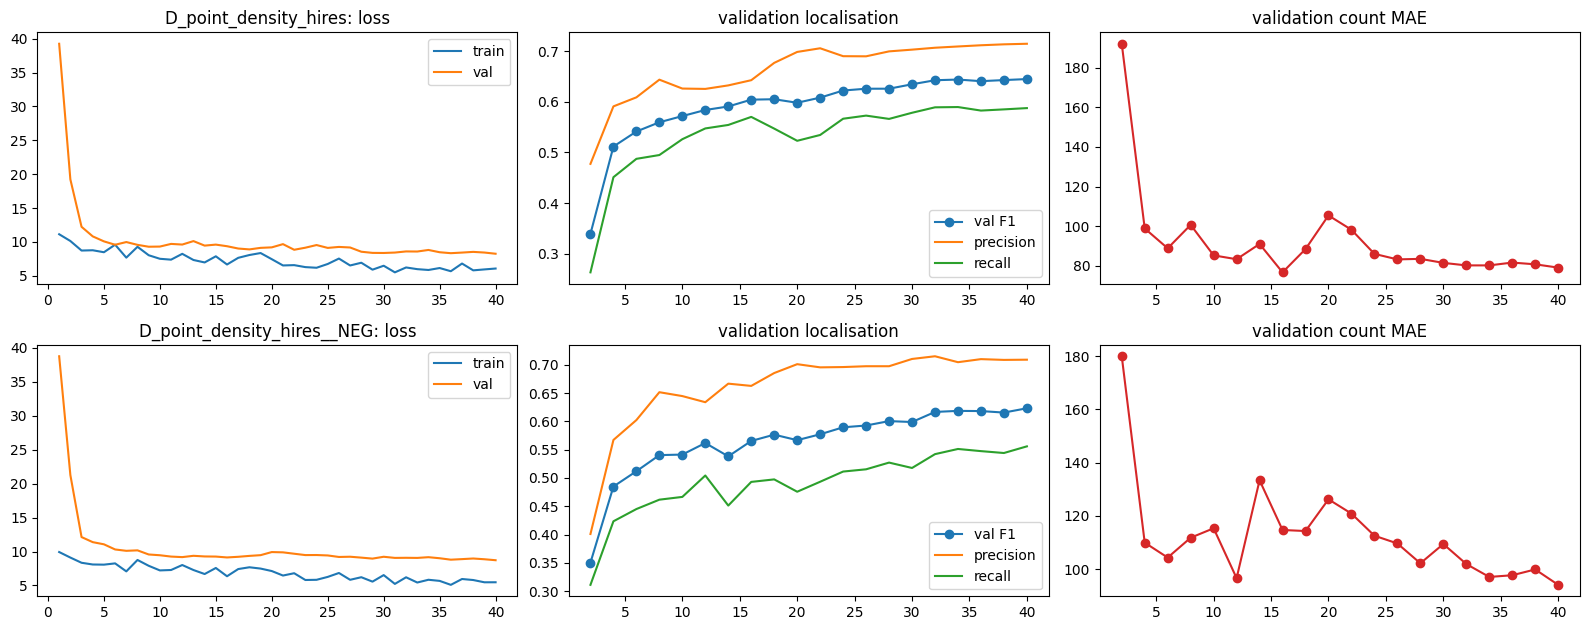

In [23]:
# ---- self-tests of the counting core (a few seconds; fail loudly if a core component is broken) ----------------------------------------
_ = run_self_tests(CFG, DEVICE_COUNT)

def import_baseline_checkpoint(path, name):
    """Use a count model you already trained (final_model.pth of the earlier notebooks) as the BASELINE: copied into the checkpoint folder so the usual
    validation-only tuning / selection treats it exactly like a freshly trained baseline."""
    ck = torch_load_safe(path, "cpu"); spec = spec_for(name)
    if any(ck["spec"].get(k) != spec.get(k) for k in ("point", "density", "point_stride")): print(f"[warn] BASELINE_COUNT_CHECKPOINT has another architecture {ck['spec']} than {name}; it is ignored."); return False
    d = os.path.join(OUT_DIR, "ckpt", name); os.makedirs(d, exist_ok=True); save_atomic({k: v for k, v in ck.items() if k != "final"}, os.path.join(d, "best.pth"))
    pd.DataFrame([dict(epoch=ck.get("epoch", 0), note="imported baseline checkpoint")]).to_csv(os.path.join(d, "history.csv"), index=False); json.dump(dict(imported=path), open(os.path.join(d, "done.json"), "w")); print(f"baseline imported from {path} -> {d}"); return True

HISTORY, BEST_CKPT, T_TRAIN = {}, {}, {}
if TRAIN_COUNT_MODEL:
    if BASELINE_COUNT_CHECKPOINT and os.path.isfile(BASELINE_COUNT_CHECKPOINT): import_baseline_checkpoint(BASELINE_COUNT_CHECKPOINT, COUNT_VARIANTS[0])
    for name in VARIANT_NAMES:
        t0 = time.time(); HISTORY[name], BEST_CKPT[name] = train_variant(name, CFG, INFER, train_samples, val_samples, DEVICE_COUNT); T_TRAIN[name] = time.time() - t0
    print("\ntraining finished:", {k: f"{v / 60:.1f} min" for k, v in T_TRAIN.items()})
    fig, axes = plt.subplots(len(VARIANT_NAMES), 3, figsize=(16, 3.2 * len(VARIANT_NAMES)), squeeze=False)
    for r, name in enumerate(VARIANT_NAMES):
        h = HISTORY[name]; ax = axes[r]; ax[0].plot(h.epoch, h.get("train_loss", h.epoch * np.nan), label="train"); ax[0].plot(h.epoch, h.get("val_loss", h.epoch * np.nan), label="val"); ax[0].set_title(f"{name}: loss"); ax[0].legend()
        if "val_F1" in h: e = h.dropna(subset=["val_F1"]); ax[1].plot(e.epoch, e.val_F1, "o-", label="val F1"); ax[1].plot(e.epoch, e.val_precision, label="precision"); ax[1].plot(e.epoch, e.val_recall, label="recall"); ax[1].legend()
        ax[1].set_title("validation localisation")
        if "val_MAE" in h: e = h.dropna(subset=["val_MAE"]); ax[2].plot(e.epoch, e.val_MAE, "o-", color="tab:red"); ax[2].set_title("validation count MAE")
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "count_training_curves.png"), dpi=100); plt.show()
else: print("TRAIN_COUNT_MODEL=False -> training skipped; the saved crowd-count model is loaded below.")


## 7. Validation tuning and selection: BASELINE vs +NEGATIVES

In [24]:
# ---- validation-only tuning (conf_accept x dup_radius grid, regional-refinement grid) and BASELINE-vs-ENHANCED selection ----------------
FINAL_COUNT_PATH = os.path.join(MODELS_DIR, "crowd_count_model.pth"); COUNT_SELECTION = {}
if TRAIN_COUNT_MODEL:
    TUNED, PRED, CACHE, _unused, VAL_TABLE = tune_variants(VARIANT_NAMES, BEST_CKPT, val_samples, DEVICE_COUNT)
    by_uid_val = {s["uid"]: s for s in train_samples + val_samples}
    for n in VARIANT_NAMES:                                              # held-out negative false positives (secondary evidence, printed only)
        rc_ = TUNED[n]["refine"] if (TUNED[n]["refine"] and TUNED[n]["refine"]["enabled"]) else None
        fp_ = negative_fp_report(PRED[n], TUNED[n]["post"], rc_, CACHE[n], NEG_POOL["heldout"], by_uid_val) if NEG_POOL["heldout"] else {}
        VAL_TABLE.loc[VAL_TABLE.variant == n, ["heldout_neg_crops", "heldout_neg_FP_per_crop"]] = [fp_.get("n_crops", 0), fp_.get("mean_fp_per_crop", np.nan)]
    display(VAL_TABLE); VAL_TABLE.to_csv(os.path.join(METRICS_DIR, "count_validation_selection.csv"), index=False)
    # ------- no-regression rule: ENHANCED (trained with negatives) is used only if validation F1 is not worse than BASELINE (original training) -------
    chosen = {}
    for b in COUNT_VARIANTS:
        base_f1 = TUNED[b]["row"]["val_F1_final"]; sel = b
        if USE_NEGATIVES and (b + "__NEG") in TUNED:
            new_f1 = TUNED[b + "__NEG"]["row"]["val_F1_final"]
            print(f"\n[{b}]  BASELINE VALIDATION F1: {base_f1:.4f}   (val MAE {TUNED[b]['row']['val_MAE']:.2f})\n[{b}]  NEW MODEL (+negatives) VALIDATION F1: {new_f1:.4f}   (val MAE {TUNED[b + '__NEG']['row']['val_MAE']:.2f})")
            if new_f1 < base_f1 + MIN_GAIN: print("    -> enhanced model is WORSE on validation: keeping BASELINE"); 
            else: sel = b + "__NEG"
            print("    SELECTED MODEL:", "ENHANCED" if sel.endswith("__NEG") else "BASELINE", f"({sel})")
        chosen[b] = sel
    SELECTED = max(chosen.values(), key=lambda n: TUNED[n]["row"]["val_F1_final"]); SEL_POST, SEL_REFINE = TUNED[SELECTED]["post"], TUNED[SELECTED]["refine"]; REFINE_ON = bool(SEL_REFINE and SEL_REFINE["enabled"])
    COUNT_SELECTION = dict(selected=SELECTED, baseline=COUNT_VARIANTS[0], enhanced_selected=SELECTED.endswith("__NEG"), val_table=VAL_TABLE.to_dict("records"))
    print(f"\nSELECTED CROWD-COUNT MODEL: {SELECTED} | conf_accept={SEL_POST['conf_accept']} dup_radius={SEL_POST['dup_radius']} | regional refinement {'ON ' + str({k: SEL_REFINE[k] for k in ('policy', 'scale', 'rel_gap')}) if REFINE_ON else 'OFF'}")
    _p, _ci = export_final_model(SELECTED, TUNED, PRED, BEST_CKPT, val_samples, SHANGHAI_ROOT, dict(notebook="CrowdRisk_All_In_One", negatives=bool(SELECTED.endswith("__NEG")), n_negatives=len(NEG_POOL["train"])), final_dir=os.path.join(COUNT_OUT, "final"))
    shutil.copy2(_p, FINAL_COUNT_PATH); print("saved ->", FINAL_COUNT_PATH)
else:
    if not os.path.isfile(FINAL_COUNT_PATH): raise FileNotFoundError(f"TRAIN_COUNT_MODEL=False but {FINAL_COUNT_PATH} does not exist (run once with TRAIN_COUNT_MODEL=True, or copy your final_model.pth there).")
    TUNED, PRED, CACHE = {}, {}, {}; SELECTED = "loaded"; print("loaded crowd-count model:", FINAL_COUNT_PATH)
PRED_FINAL, CK_FINAL = load_model_checkpoint(FINAL_COUNT_PATH, DEVICE_COUNT); FINAL_POST = {k: PRED_FINAL.cfg[k] for k in ("conf_accept", "uncertain_ratio", "dup_radius")}
FINAL_REFINE = PRED_FINAL.cfg["refine"] if PRED_FINAL.cfg["refine"].get("enabled", False) else None; FINAL_CACHE = os.path.join(OUT_DIR, "eval_cache", f"final_{file_fingerprint(FINAL_COUNT_PATH)}")
COUNT_INFO = dict(variant=CK_FINAL.get("variant"), trained_with_negatives=str(CK_FINAL.get("variant", "")).endswith("__NEG"), post=FINAL_POST, refinement=bool(FINAL_REFINE))
print("FINAL crowd-count model:", COUNT_INFO)


,variant,kind,conf_accept,dup_radius,val_F1,val_precision,val_recall,val_MAE,val_bias,refine_enabled,val_F1_refined,refine_policy,refine_scale,refine_rel_gap,val_F1_final,heldout_neg_crops,heldout_neg_FP_per_crop
0,D_point_density_hires,point,0.3,4.0,0.657046,0.657444,0.656649,45.29,-0.37,True,0.681866,replace_if_more,2.0,0.45,0.681866,0.0,NaN
1,D_point_density_hires__NEG,point,0.2,4.0,0.651963,0.621506,0.685558,52.15,31.55,True,0.669709,replace_if_more,1.5,0.25,0.669709,0.0,NaN



[D_point_density_hires]  BASELINE VALIDATION F1: 0.6819   (val MAE 45.29)
[D_point_density_hires]  NEW MODEL (+negatives) VALIDATION F1: 0.6697   (val MAE 52.15)
    -> enhanced model is WORSE on validation: keeping BASELINE
    SELECTED MODEL: BASELINE (D_point_density_hires)

SELECTED CROWD-COUNT MODEL: D_point_density_hires | conf_accept=0.3 dup_radius=4.0 | regional refinement ON {'policy': 'replace_if_more', 'scale': 2.0, 'rel_gap': 0.45}
reload check on validation image A_train_IMG_101: the saved model loads and predicts 396 points (ground truth 298).
SAVED -> c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs\work\count\final ['config.json', 'final_model.pth', 'inference_config.json']
selected: D_point_density_hires | conf_accept=0.3 dup_radius=4.0 | refinement ON | count calibration OFF (no cross-validated gain on validation)
saved -> c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs\models\crowd_count_model.pth
FINAL crowd-count mode

## 8. Test evaluation (first and only use of the official test folders)

In [25]:
# ---- FINAL TEST evaluation of the crowd-count model (first and only use of the official ShanghaiTech test folders) --------------------------
COUNT_TEST, COUNT_TEST_TABLE, KEPT_FINAL = {}, pd.DataFrame(), {}
if COUNT_DATA_OK:
    TEST_SAMPLES = subsample(test_samples, CFG["eval_max_images"]) if CFG["eval_max_images"] else test_samples
    print(f"evaluating {len(TEST_SAMPLES)} held-out test images (Part A: {sum(s['part'] == 'A' for s in TEST_SAMPLES)}, Part B: {sum(s['part'] == 'B' for s in TEST_SAMPLES)})")
    FINAL_DF, KEPT_FINAL = evaluate_samples(PRED_FINAL, TEST_SAMPLES, FINAL_POST, CFG, "point", FINAL_CACHE, FINAL_REFINE, "test FINAL", keep=True); FINAL_DF.to_csv(os.path.join(PRED_DIR, "count_test_per_image.csv"), index=False)
    COUNT_TEST_TABLE = report_table(FINAL_DF, CFG, "FINAL"); display(COUNT_TEST_TABLE.round(3)); COUNT_TEST_TABLE.to_csv(os.path.join(METRICS_DIR, "count_test_metrics.csv"), index=False)
    _c = COUNT_TEST_TABLE[COUNT_TEST_TABLE.subset == "Combined"].iloc[0]; COUNT_TEST = {k: float(_c[k]) for k in ("MAE", "RMSE", "NAE", "precision", "recall", "F1", "loc_err_px")}
    print("COUNT TEST (Combined):", {k: round(v, 4) for k, v in COUNT_TEST.items()})
    if TRAIN_COUNT_MODEL and REPORT_BASELINE_ON_TEST and USE_NEGATIVES and len(COUNT_VARIANT_NAMES) > 1:      # comparison REPORT only - the choice was made on validation
        rows = []
        for n in COUNT_VARIANT_NAMES:
            rc_ = TUNED[n]["refine"] if (TUNED[n]["refine"] and TUNED[n]["refine"]["enabled"]) else None
            d_ = evaluate_samples(PRED[n], TEST_SAMPLES, TUNED[n]["post"], CFG, "point", CACHE[n], rc_, f"test {n}"); s_ = summarize(d_, CFG)
            rows.append(dict(model=n + ("  [ENHANCED: +negatives]" if n.endswith("__NEG") else "  [BASELINE]"), selected=(n == SELECTED), **{k: s_[k] for k in ("MAE", "RMSE", "NAE", "precision", "recall", "F1", "loc_err_px")}))
        CMP = pd.DataFrame(rows); display(CMP.round(4)); CMP.to_csv(os.path.join(METRICS_DIR, "count_baseline_vs_enhanced_test_report.csv"), index=False); print("(report only: the selection above was made on VALIDATION images)")
else: print("[info] ShanghaiTech not available -> no count test metrics in this run.")
# ---- hand-over to the next notebooks: what was selected + test metrics (the model itself is <OUTPUT_DIR>/models/crowd_count_model.pth) ----------------------------
json.dump(json_safe(dict(count_info=COUNT_INFO, test=COUNT_TEST, selection=COUNT_SELECTION, negatives=RUN_META.get("negatives"), seed=SEED)), open(os.path.join(MODELS_DIR, "crowd_count_info.json"), "w"), indent=2)
print("saved ->", os.path.join(MODELS_DIR, "crowd_count_info.json"))


evaluating 498 held-out test images (Part A: 182, Part B: 316)


,model,subset,n,MAE,RMSE,NAE,NAE_floor10,bias,precision,recall,...,F1_fixed_tol,loc_err_px,dup_rate,TP,FP,dup,spurious,FN,gt_total,pred_total
0,FINAL,Part A,182,91.984,135.930,0.238,0.238,57.918,0.630,0.714,...,0.728,2.870,0.050,56338,33065,4457,28608,22524,78862,89403
1,FINAL,Part B,316,12.101,26.066,0.114,0.114,0.108,0.734,0.735,...,0.743,3.060,0.040,28736,10419,1550,8869,10385,39121,39155
2,FINAL,Combined,498,41.295,84.757,0.159,0.159,21.235,0.662,0.721,...,0.733,2.935,0.047,85074,43484,6007,37477,32909,117983,128558
3,FINAL,Combined / low density,176,8.875,30.513,0.152,0.152,1.932,0.747,0.771,...,0.702,3.873,0.050,8041,2730,540,2190,2390,10431,10771
4,FINAL,Combined / medium density,246,32.260,52.709,0.151,0.151,15.797,0.685,0.737,...,0.722,3.127,0.048,37739,17354,2637,14717,13468,51207,55093
5,FINAL,Combined / high density,76,145.618,189.535,0.203,0.203,83.539,0.627,0.697,...,0.747,2.558,0.045,39294,23400,2830,20570,17051,56345,62694
6,FINAL,Part A / low density,7,45.714,94.873,0.658,0.658,25.429,0.536,0.703,...,0.551,3.872,0.063,402,348,47,301,170,572,750
7,FINAL,Part A / medium density,108,53.722,74.584,0.225,0.225,33.741,0.655,0.746,...,0.702,3.408,0.056,19561,10287,1684,8603,6643,26204,29848
8,FINAL,Part A / high density,67,158.493,200.708,0.216,0.216,100.284,0.619,0.698,...,0.743,2.570,0.046,36375,22430,2726,19704,15711,52086,58805
9,FINAL,Part B / low density,169,7.349,24.429,0.131,0.131,0.959,0.762,0.775,...,0.712,3.873,0.049,7639,2382,493,1889,2220,9859,10021


COUNT TEST (Combined): {'MAE': 41.2952, 'RMSE': 84.7568, 'NAE': 0.1594, 'precision': 0.6618, 'recall': 0.7211, 'F1': 0.6901, 'loc_err_px': 2.9346}


,model,selected,MAE,RMSE,NAE,precision,recall,F1,loc_err_px
0,D_point_density_hires [BASELINE],True,41.2952,84.7568,0.1594,0.6618,0.7211,0.6901,2.9346
1,D_point_density_hires__NEG [ENHANCED: +negati...,False,52.0020,106.8421,0.1770,0.6303,0.7402,0.6808,2.9630


(report only: the selection above was made on VALIDATION images)
saved -> c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs\models\crowd_count_info.json


## 9. Visualisation and summary

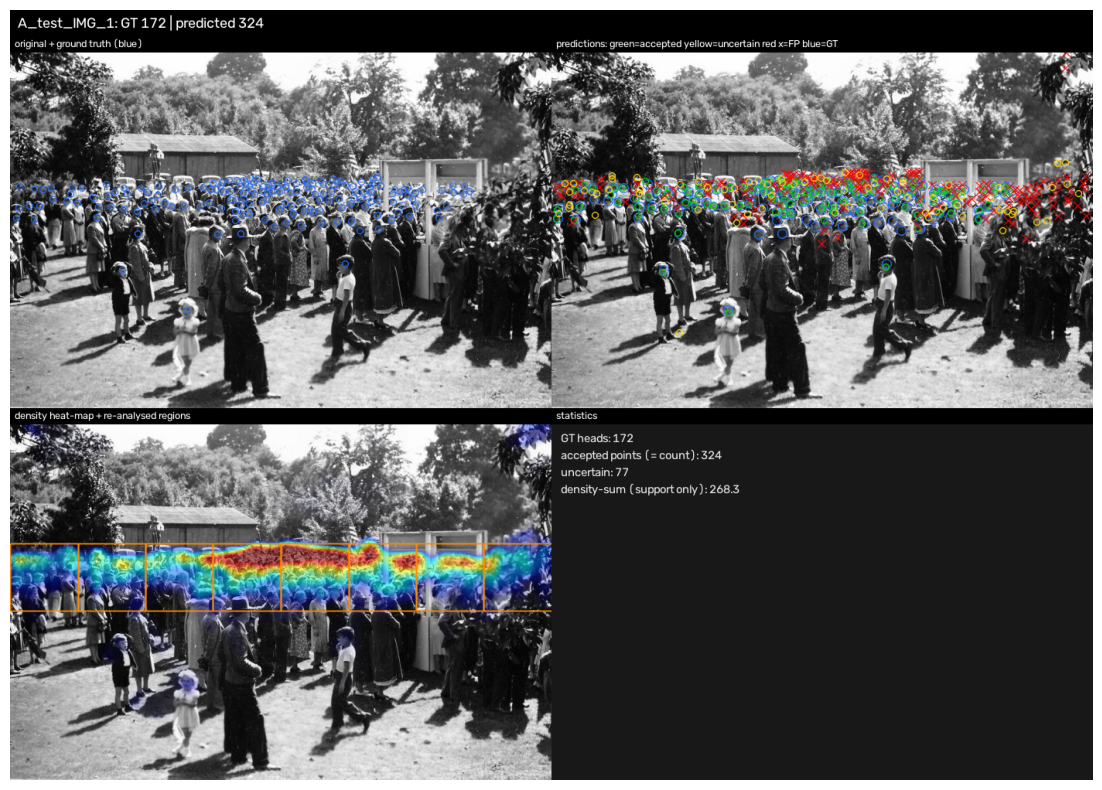

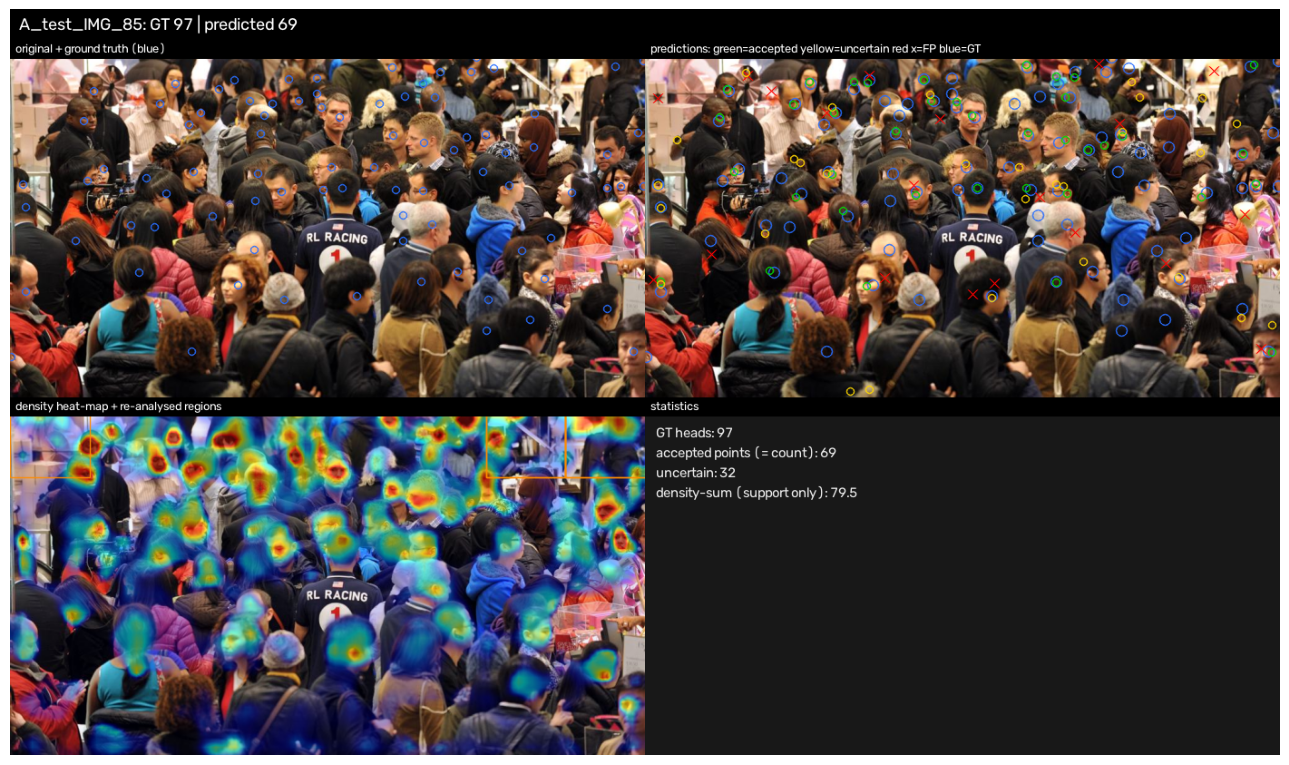

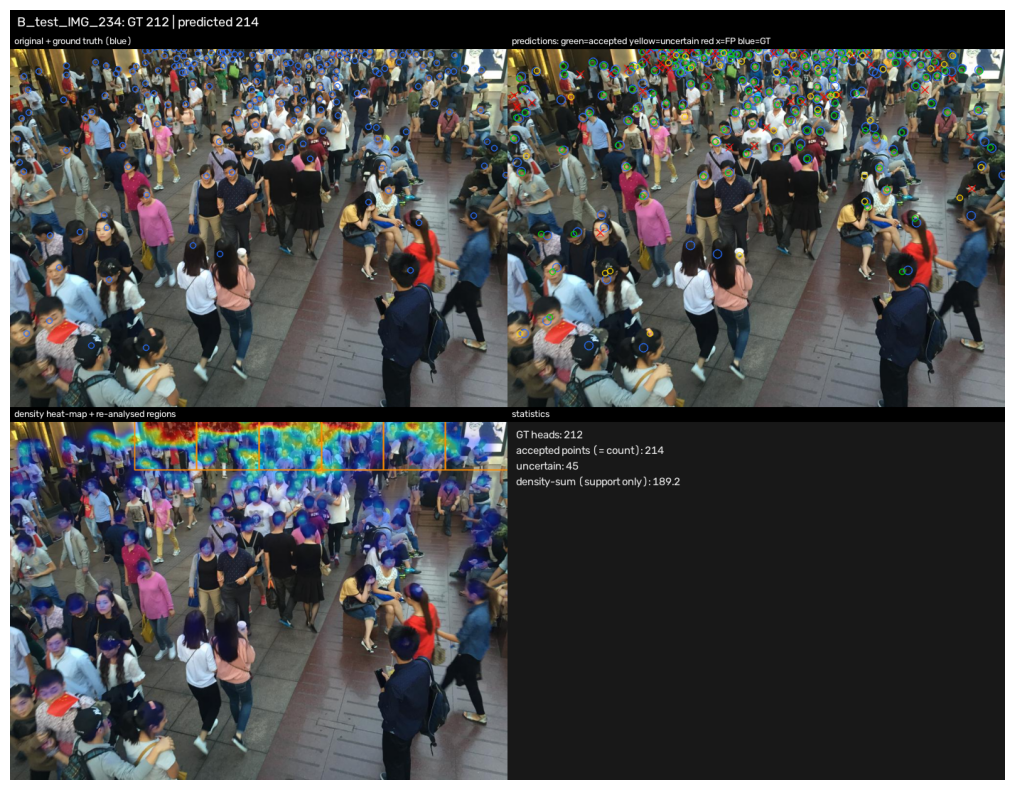

In [26]:
# ---- crowd-count visualisation (original | predictions | density heat-map | statistics) ------------------------------------------------
if KEPT_FINAL:
    _uids = list(KEPT_FINAL)[:: max(1, len(KEPT_FINAL) // 3)][:3]; _by = {s["uid"]: s for s in TEST_SAMPLES}
    for u in _uids:
        raw_, fin_, st_, info_ = KEPT_FINAL[u]; s_ = _by[u]; img_ = read_image_rgb(s_["img"])
        panel = render_panel(img_, fin_, gt=s_["pts"], status=st_, density=raw_.get("density"), cell_xy=raw_.get("cell_xy"), regions=[dict(box=i["box"]) for i in info_], title=f"{u}: GT {s_['count']} | predicted {fin_['count']}",
                             stats=[f"GT heads: {s_['count']}", f"accepted points (= count): {fin_['count']}", f"uncertain: {len(fin_['uncertain'])}", f"density-sum (support only): {raw_['density'].sum():.1f}" if raw_.get("density") is not None else "density: n/a"], panel_w=700)
        plt.figure(figsize=(13, 8)); plt.imshow(panel); plt.axis("off"); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, f"count_{u}.png"), dpi=90); plt.show()


In [27]:
print("=" * 90); print("NOTEBOOK 01 - SUMMARY"); print("=" * 90)
print("Selected crowd-count model :", COUNT_INFO.get("variant"), "| trained with hard negatives:", COUNT_INFO.get("trained_with_negatives"), "| thresholds:", COUNT_INFO.get("post"), "| regional refinement:", COUNT_INFO.get("refinement"))
print("Test metrics (ShanghaiTech)  :", {k: round(v, 4) for k, v in COUNT_TEST.items()} if COUNT_TEST else "n/a (ShanghaiTech not available in this run)")
print("Model file                   :", FINAL_COUNT_PATH, "\nNext: notebook 02_Motion_Model")


NOTEBOOK 01 - SUMMARY
Selected crowd-count model : D_point_density_hires | trained with hard negatives: False | thresholds: {'conf_accept': 0.3, 'uncertain_ratio': 0.5, 'dup_radius': 4.0} | regional refinement: True
Test metrics (ShanghaiTech)  : {'MAE': 41.2952, 'RMSE': 84.7568, 'NAE': 0.1594, 'precision': 0.6618, 'recall': 0.7211, 'F1': 0.6901, 'loc_err_px': 2.9346}
Model file                   : c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs\models\crowd_count_model.pth 
Next: notebook 02_Motion_Model


## Limitations
TUB CrowdFlow has no head annotations, so this model is supervised and tested on ShanghaiTech. The ShanghaiTech test numbers say nothing about domain shift to TUB or to your own videos. The negative crops come from ShanghaiTech *train* images; there is no negative test split (held-out negatives from validation images are used instead).